# IN_TOUCH v27 — Top-60 Data-Ranked Edition
## Changelog v26 → v27

### 🎯 Validation Strategy (v27 core change)
- **D_val (MS-ASL) is now the primary early-stopping signal** — signer-independent split, real wild-domain videos
- **E_val (Sem-Lex) removed from val** — too clean / lab-controlled, caused over-optimistic stopping
- **B_val kept as benchmark diagnostic only** — evaluated after training, never drives checkpoint saving
- **D_test added to final evaluation** — signer-independent real-world test set

### 🏗️ Architecture (v27)
- base_channels = 64 (power-of-2, down from 63; keeps ~750K params — right-sized for ~3700 samples)
- tcn_dropout = 0.28 (reduced slightly; SE + SpatialAttn already regularise well)
- T0_RESTART = 40 → troughs at 40/80/160/280 = 4 snapshots within 350 epochs
- All v26 attention upgrades preserved: SE blocks, SpatialAttention, DropPath, MultiHeadTA

### ⚡ Training (v27)
- Early stopping criterion: D_val Top-1 (signer-independent)
- Parameterization guard: warns if model is overparameterized for dataset size
- Cross-source data health diagnostic printed before training
- Restart schedule: T0=40, T_mult=2 → 4 snapshot checkpoints at real troughs

### 📊 Evaluation (v27)
- Primary stopping: D_val (MS-ASL signer-independent)
- Post-training diagnostics: B_val, E_val, D_val, B_test, E_test, D_test
- Summary table includes all splits clearly labelled with their role


In [1]:
# CELL 1 — Local Setup
# pip install mediapipe opencv-python tqdm scikit-learn pandas matplotlib torch torchvision
import sys, platform
print("Python executable:", sys.executable)
print("Platform:", platform.platform())
print("Local setup ready ✓")


Python executable: h:\Graduation project\.venv\Scripts\python.exe
Platform: Windows-10-10.0.19045-SP0
Local setup ready ✓


In [2]:
# CELL 2 — Imports & Seed
import os, cv2, json, glob, copy as cp, pickle, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts, LinearLR, SequentialLR
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm
from collections import Counter
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings; warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False
print("Imports done ✓")


Imports done ✓


In [3]:
# CELL 3 — Local Paths & Config
# v27: D_val = primary stopping signal | E_val = diagnostic only | B_val = benchmark only
PROJECT_ROOT = r"H:\Graduation project"

USE_BODYLOC_LANDMARKS = False
LANDMARK_MODE_NAME    = "ordinary_hands_pose"

WLASL_VIDEOS_DIR   = os.path.join(PROJECT_ROOT, "WLASL DATA")
WLASL_OUT_POSE     = os.path.join(PROJECT_ROOT, "WLASL_landmarks_v14_pose")
WLASL_OUT_HANDS    = os.path.join(PROJECT_ROOT, "WLASL_landmarks")
WLASL100_TRAIN_DIR = os.path.join(PROJECT_ROOT, "New Dataa", "train", "frames")
WLASL100_VAL_DIR   = os.path.join(PROJECT_ROOT, "New Dataa", "val",   "frames")
WLASL100_TEST_DIR  = os.path.join(PROJECT_ROOT, "New Dataa", "test",  "frames")
WLASL100_OUT_POSE  = os.path.join(PROJECT_ROOT, "wlasl100_landmarks_v14_pose")
WLASL100_OUT_HANDS = os.path.join(PROJECT_ROOT, "wlasl100_landmarks")
X_C_PATH           = os.path.join(PROJECT_ROOT, "X_c.npy")
Y_C_PATH           = os.path.join(PROJECT_ROOT, "y_c.npy")
C_LABELMAP_PATHS   = [
    os.path.join(PROJECT_ROOT, "source_c_label_to_id.pkl"),
    os.path.join(PROJECT_ROOT, "source_c_words.npy"),
    os.path.join(PROJECT_ROOT, "labels_c.pkl"),
]
MSASL_OUT_POSE     = os.path.join(PROJECT_ROOT, "MSASL_landmarks_pose")
MSASL_OUT_HANDS    = os.path.join(PROJECT_ROOT, "MSASL_landmarks_hands")
MODEL_PATH         = os.path.join(PROJECT_ROOT, "hand_landmarker.task")
POSE_MODEL_PATH    = os.path.join(PROJECT_ROOT, "pose_landmarker_heavy.task")
FACE_MODEL_PATH    = os.path.join(PROJECT_ROOT, "face_landmarker.task")
SAMPLES_JSON_PATH  = os.path.join(PROJECT_ROOT, "samples.json")
WLASL_JSON_PATH    = os.path.join(PROJECT_ROOT, "WLASL_v0.3.json")
SEMLEX_OUT_DIR     = os.path.join(PROJECT_ROOT, "filtered_100_words_extracted")

OUTPUT_DIR      = os.path.join(PROJECT_ROOT, "outputs_v27_top60")
os.makedirs(OUTPUT_DIR, exist_ok=True)
SAVE_PATH_MODEL = os.path.join(OUTPUT_DIR, "stgcn_best_v27_top60.pth")
SAVE_PATH_META  = os.path.join(OUTPUT_DIR, "stgcn_meta_v27_top60.pkl")
SNAPSHOT_DIR    = os.path.join(OUTPUT_DIR, "snapshots_v27")
os.makedirs(SNAPSHOT_DIR, exist_ok=True)

# ── core constants ──────────────────────────────────────────────────────────
IN_CHANNELS   = 6
SAMPLE_EVERY  = 1
TARGET_FRAMES = 64
MAX_NUM_HANDS = 2
NUM_JOINTS    = 57
MIN_VIDEOS    = 10

# ── source flags ────────────────────────────────────────────────────────────
USE_SOURCE_C        = True
USE_SOURCE_D        = True
USE_SOURCE_E        = True

# Train composition — never leak val/test splits into training
USE_D_VAL_IN_TRAIN  = False
USE_D_TEST_IN_TRAIN = False
USE_E_VAL_IN_TRAIN  = False
USE_E_TEST_IN_TRAIN = False

# ── v27 VAL STRATEGY ────────────────────────────────────────────────────────
# D_val = PRIMARY stopping signal (MS-ASL: signer-independent, real wild videos)
# E_val = diagnostic only — evaluated post-training, never drives checkpoint saving
# B_val = benchmark reference — evaluated post-training
USE_D_VAL_IN_VAL = True    # ← drives early stopping
USE_E_VAL_IN_VAL = False   # ← diagnostic only (too clean for stopping)

# ── test composition ─────────────────────────────────────────────────────────
USE_E_TEST_IN_TEST = True   # Sem-Lex test as additional eval split
USE_D_TEST_IN_TEST = True   # MS-ASL test — signer-independent real-world test

SOURCE_C_USE_ALL       = False
SOURCE_C_CAP_PER_CLASS = 15
USE_MIRROR_AUG = False
FLIP_WLASL     = False
FLIP_TEST      = False

# v27: snapshot ensemble state
SNAPSHOT_ENSEMBLE_PATHS = []

# ── v27 ARCH PARAMS ─────────────────────────────────────────────────────────
# base_channels=64 (power-of-2, right-sized for ~3700 samples; ~750K params)
# tcn_dropout=0.28 (slightly reduced; SE+SpatialAttn carry the regularisation)
ARCH_PARAMS = dict(
    in_channels    = 6,
    base_channels  = 64,
    num_stages     = 6,
    inflate_stages = [3],
    down_stages    = [3],
    tcn_dropout    = 0.28,
)

POSE_WORDS = [
    "apple","bed","black","brown","candy","clothes","color","cool",
    "cousin","cow","deaf","doctor","drink","eat","enjoy","fine","forget",
    "full","hat","hearing","hot","jacket","kiss","letter","like","man",
    "mother","orange","pink","pizza","secretary","shirt","son","tell",
    "time","white","who","woman","wrong"
]
HAND_ONLY_WORDS = [
    "accident","africa","all","basketball","before","bird","birthday",
    "blue","book","bowling","but","can","chair","change","cheat","city",
    "computer","cook","corn","dance","dark","decide","dog","family",
    "finish","fish","give","go","graduate","help","how","language","last",
    "later","many","medicine","meet","need","no","now","paint","paper",
    "play","pull","purple","right","same","school","short","study","table",
    "tall","thanksgiving","thin","thursday","walk","want","what","work",
    "year","yes"
]
ALL_100_POSE_WORDS      = list(POSE_WORDS)
ALL_100_HAND_ONLY_WORDS = list(HAND_ONLY_WORDS)
ALL_100_WORDS           = ALL_100_POSE_WORDS + ALL_100_HAND_ONLY_WORDS
ALL_WORDS               = list(ALL_100_WORDS)
TOP_K_WORDS              = 60
MIN_TRAIN_TOTAL_FOR_TOPK = 40
MIN_VAL_TOTAL_FOR_TOPK   = 5
MIN_B_TEST_FOR_TOPK      = 2

for d in [WLASL_OUT_POSE, WLASL_OUT_HANDS, WLASL100_OUT_POSE,
          WLASL100_OUT_HANDS, MSASL_OUT_POSE, MSASL_OUT_HANDS, OUTPUT_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"PROJECT_ROOT  : {PROJECT_ROOT}")
print(f"LANDMARK_MODE : {LANDMARK_MODE_NAME}")
print(f"Full word pool={len(ALL_WORDS)} | target top_k={TOP_K_WORDS}")
print(f"Source C cap  : {SOURCE_C_CAP_PER_CLASS}/class")
print(f"Output dir    : {OUTPUT_DIR}")
print(f"\nv27 Val strategy:")
print(f"  Stopping signal : D_val (MS-ASL signer-independent)")
print(f"  Diagnostic      : B_val (WLASL100 benchmark), E_val (Sem-Lex upper bound)")
print(f"\nv27 Arch: base_ch={ARCH_PARAMS['base_channels']} | "
      f"stages={ARCH_PARAMS['num_stages']} | dropout={ARCH_PARAMS['tcn_dropout']}")

path_checks = {
    "Project root":     PROJECT_ROOT,
    "Source A videos":  WLASL_VIDEOS_DIR,
    "Source A hands":   WLASL_OUT_HANDS,
    "Source A pose":    WLASL_OUT_POSE,
    "Source B train":   WLASL100_TRAIN_DIR,
    "Source B val":     WLASL100_VAL_DIR,
    "Source B test":    WLASL100_TEST_DIR,
    "Source B hands":   WLASL100_OUT_HANDS,
    "Source B pose":    WLASL100_OUT_POSE,
    "Source C X_c.npy": X_C_PATH,
    "Source C y_c.npy": Y_C_PATH,
    "Source D hands":   MSASL_OUT_HANDS,
    "Source D pose":    MSASL_OUT_POSE,
    "Hand model task":  MODEL_PATH,
    "Pose model task":  POSE_MODEL_PATH,
    "Face model task":  FACE_MODEL_PATH,
    "samples.json":     SAMPLES_JSON_PATH,
    "WLASL_v0.3.json":  WLASL_JSON_PATH,
    "Output dir":       OUTPUT_DIR,
    "Source E dir":     SEMLEX_OUT_DIR,
}
print("\nLocal path check:")
for name, path in path_checks.items():
    status = "OK     " if os.path.exists(path) else "MISSING"
    print(f"  {status} | {name:28s} | {path}")
print("\nLabel map candidates:")
for p in C_LABELMAP_PATHS:
    print(("  OK      | " if os.path.exists(p) else "  MISSING | ") + p)


PROJECT_ROOT  : H:\Graduation project
LANDMARK_MODE : ordinary_hands_pose
Full word pool=100 | target top_k=60
Source C cap  : 15/class
Output dir    : H:\Graduation project\outputs_v27_top60

v27 Val strategy:
  Stopping signal : D_val (MS-ASL signer-independent)
  Diagnostic      : B_val (WLASL100 benchmark), E_val (Sem-Lex upper bound)

v27 Arch: base_ch=64 | stages=6 | dropout=0.28

Local path check:
  OK      | Project root                 | H:\Graduation project
  OK      | Source A videos              | H:\Graduation project\WLASL DATA
  OK      | Source A hands               | H:\Graduation project\WLASL_landmarks
  OK      | Source A pose                | H:\Graduation project\WLASL_landmarks_v14_pose
  OK      | Source B train               | H:\Graduation project\New Dataa\train\frames
  OK      | Source B val                 | H:\Graduation project\New Dataa\val\frames
  OK      | Source B test                | H:\Graduation project\New Dataa\test\frames
  OK      | Source 

In [4]:
# CELL 4 — MediaPipe Init
hand_landmarker = vision.HandLandmarker.create_from_options(
    vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=MODEL_PATH),
        num_hands=MAX_NUM_HANDS))
pose_landmarker = vision.PoseLandmarker.create_from_options(
    vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=POSE_MODEL_PATH),
        output_segmentation_masks=False))
face_landmarker = vision.FaceLandmarker.create_from_options(
    vision.FaceLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=FACE_MODEL_PATH),
        output_face_blendshapes=False, num_faces=1))
print("MediaPipe initialized ✓")


MediaPipe initialized ✓


In [5]:
# CELL 5 — Pipeline Functions
# v25: fixed hand dominance (Right=dominant)
# v26: no changes needed here — pipeline already correct
POSE_USEFUL = [0, 11, 12, 13, 14, 15, 16, 23, 24]
FACE_USEFUL = [1, 4, 13, 14, 17, 61]


def normalize_hand(coords, min_scale=0.01):
    coords = coords.astype(np.float32, copy=True)
    wrist  = coords[0].copy()
    coords = coords - wrist
    scale  = float(np.linalg.norm(coords[9]))
    if (not np.isfinite(scale)) or scale < min_scale:
        return np.zeros_like(coords, dtype=np.float32)
    return (coords / scale).astype(np.float32)


def extract_hands(frame_bgr, flip_hands=False):
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB,
                      data=cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    res = hand_landmarker.detect(mp_img)
    out = []
    if res.hand_landmarks:
        for i, lms in enumerate(res.hand_landmarks):
            label, conf = "Unknown", 1.0
            if res.handedness and i < len(res.handedness) and res.handedness[i]:
                label = res.handedness[i][0].category_name
                conf  = float(res.handedness[i][0].score)
            if flip_hands:
                label = "Left" if label == "Right" else "Right"
            out.append({"label": label, "confidence": conf,
                        "landmarks": [{"x": float(lm.x), "y": float(lm.y),
                                       "z": float(lm.z)} for lm in lms]})
    return out


def extract_pose_joints(frame_bgr):
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB,
                      data=cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    res    = pose_landmarker.detect(mp_img)
    coords = np.zeros((9, 3), dtype=np.float32)
    if res.pose_landmarks:
        lms = res.pose_landmarks[0]
        for oi, ii in enumerate(POSE_USEFUL):
            if ii < len(lms):
                coords[oi] = [lms[ii].x, lms[ii].y, lms[ii].z]
    return coords


def extract_face_joints(frame_bgr):
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB,
                      data=cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    res    = face_landmarker.detect(mp_img)
    coords = np.zeros((6, 3), dtype=np.float32)
    if res.face_landmarks:
        lms = res.face_landmarks[0]
        for oi, ii in enumerate(FACE_USEFUL):
            if ii < len(lms):
                coords[oi] = [lms[ii].x, lms[ii].y, lms[ii].z]
    return coords


def frame_to_skeleton_v13(frame_bgr, flip_hands=None):
    """Dominant = Right hand (by label), Passive = Left hand. Fixed in v25."""
    if flip_hands is None:
        flip_hands = FLIP_WLASL
    hands = extract_hands(frame_bgr, flip_hands=flip_hands)

    dominant = np.zeros((21, 3), dtype=np.float32)
    passive  = np.zeros((21, 3), dtype=np.float32)

    right_cands = [h for h in hands if h["label"] == "Right"]
    left_cands  = [h for h in hands if h["label"] == "Left"]
    right_cands.sort(key=lambda h: h["confidence"], reverse=True)
    left_cands.sort( key=lambda h: h["confidence"], reverse=True)

    def _to_coords(hand):
        lms    = hand.get("landmarks", [])
        coords = np.array([[l["x"], l["y"], l["z"]] for l in lms], dtype=np.float32)
        if coords.shape == (21, 3):
            return normalize_hand(coords)
        return np.zeros((21, 3), dtype=np.float32)

    if right_cands:
        dominant = _to_coords(right_cands[0])
    if left_cands:
        passive = _to_coords(left_cands[0])

    if np.abs(dominant).sum() < 1e-6 and np.abs(passive).sum() < 1e-6 and hands:
        best = max(hands, key=lambda h: h["confidence"])
        dominant = _to_coords(best)

    pose = extract_pose_joints(frame_bgr)
    face = extract_face_joints(frame_bgr)
    return np.concatenate([dominant, passive, pose, face], axis=0)  # (57, 3)


def frame_to_skeleton_legacy(frame_dict):
    dominant = np.zeros((21, 3), dtype=np.float32)
    passive  = np.zeros((21, 3), dtype=np.float32)
    for si, hand in enumerate(frame_dict.get("hands", [])[:2]):
        lms    = hand.get("landmarks", [])
        coords = np.array([[lm.get("x",0), lm.get("y",0), lm.get("z",0)]
                           for lm in lms], dtype=np.float32)
        if coords.shape == (21, 3):
            coords = normalize_hand(coords)
            if si == 0: dominant = coords
            else:       passive  = coords
    return np.concatenate([dominant, passive, np.zeros((15, 3), dtype=np.float32)], axis=0)


def to_stgcn_tensor(sequence):
    """(T, 57, 3) → (6, T, 57, 1)"""
    vel = np.zeros_like(sequence)
    vel[1:] = sequence[1:] - sequence[:-1]
    combined = np.concatenate([sequence, vel], axis=-1)  # (T, 57, 6)
    t = np.transpose(combined, (2, 0, 1))                # (6, T, 57)
    return np.expand_dims(t, axis=-1).astype(np.float32) # (6, T, 57, 1)


def fix_tensor_length(tensor, target=TARGET_FRAMES):
    T = tensor.shape[1]
    if T == target: return tensor
    if T == 0:
        return np.zeros((tensor.shape[0], target, tensor.shape[2], 1), dtype=np.float32)
    idx = np.round(np.linspace(0, T - 1, target)).astype(int)
    return tensor[:, idx, :, :].astype(np.float32)


def _atomic_write(data, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f: json.dump(data, f)
    os.replace(tmp, path)


def normalize_vid_id(raw_id):
    raw_id = os.path.splitext(raw_id)[0]
    return (raw_id.lstrip("0") or "0").lower()


print("Pipeline functions defined ✓ (v26 — same as v25, all fixes preserved)")


Pipeline functions defined ✓ (v26 — same as v25, all fixes preserved)


In [6]:
# CELL 5V — Landmark Visualization (unchanged from v25)
HAND_CONN = [
    (0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),
    (0,9),(9,10),(10,11),(11,12),(0,13),(13,14),(14,15),(15,16),
    (0,17),(17,18),(18,19),(19,20),(5,9),(9,13),(13,17)
]
POSE_CONN = [(0,1),(0,2),(1,3),(2,4),(3,5),(4,6),(1,7),(2,8)]


def draw_skeleton(frame_bgr, sk57, word=None, frame_idx=None):
    h, w = frame_bgr.shape[:2]
    out  = frame_bgr.copy()
    R    = max(4, min(h, w) // 100)
    TH   = max(1, R // 2)
    C_DOM  = (0, 255, 0); C_PAS  = (255, 100, 0)
    C_POSE = (0, 0, 220); C_FACE = (0, 220, 220)

    def to_px(xn, yn):
        return (int(np.clip(xn, 0, 1) * w), int(np.clip(yn, 0, 1) * h))

    pose_blk = sk57[42:51]
    pose_px  = []
    for j in pose_blk:
        if abs(j[0]) > 1e-6 or abs(j[1]) > 1e-6:
            pose_px.append(to_px(j[0], j[1]))
        else:
            pose_px.append(None)
    for (a, b) in POSE_CONN:
        if a < len(pose_px) and b < len(pose_px) and pose_px[a] and pose_px[b]:
            cv2.line(out, pose_px[a], pose_px[b], C_POSE, TH)
    for pt in pose_px:
        if pt: cv2.circle(out, pt, R+1, C_POSE, -1)
    for j in sk57[51:57]:
        if abs(j[0]) > 1e-6 or abs(j[1]) > 1e-6:
            cv2.circle(out, to_px(j[0], j[1]), R, C_FACE, -1)

    r_wrist = pose_blk[6]; l_wrist = pose_blk[7]
    scale   = 0.15

    def draw_hand(joints_wr, anchor, color):
        if np.abs(joints_wr).sum() < 1e-4: return
        anch = anchor if (abs(anchor[0]) > 1e-6) else np.array([0.5, 0.65, 0.0])
        pts = [(int(np.clip(anch[0]+joints_wr[j,0]*scale,0,1)*w),
                int(np.clip(anch[1]+joints_wr[j,1]*scale,0,1)*h))
               for j in range(21)]
        for (a, b) in HAND_CONN:
            cv2.line(out, pts[a], pts[b], color, TH)
        for pt in pts:
            cv2.circle(out, pt, R, color, -1)

    draw_hand(sk57[:21],   r_wrist, C_DOM)
    draw_hand(sk57[21:42], l_wrist, C_PAS)
    dom_zero  = np.abs(sk57[:21]).sum()   < 1e-4
    pas_zero  = np.abs(sk57[21:42]).sum() < 1e-4
    pose_zero = np.abs(sk57[42:51]).sum() < 1e-4
    status = []
    if dom_zero:  status.append("NO_DOM")
    if pas_zero:  status.append("no_pas")
    if pose_zero: status.append("NO_POSE")
    status_str = "  ".join(status) if status else "all detected"
    cv2.putText(out, status_str, (8, h-12), cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                (0,0,255) if dom_zero else (0,255,0), 2)
    if word:
        cv2.putText(out, word, (8, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255,255,255), 2)
    if frame_idx is not None:
        cv2.putText(out, f"f{frame_idx}", (w-55,25), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (200,200,200), 1)
    return out


def visualize_video(video_path, max_frames=80, flip=False, word=None,
                    output_path=None, show_skeleton_only=False):
    if output_path is None:
        base = os.path.splitext(os.path.basename(video_path))[0]
        output_path = os.path.join(OUTPUT_DIR, f"viz_{base}_flip{flip}.mp4")
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    ow  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    oh  = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    out_w = ow if show_skeleton_only else ow * 2
    writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (out_w, oh))
    n0 = n1 = n2 = fi = 0
    all_skeletons = []
    print(f"Visualizing: {os.path.basename(video_path)} | flip={flip}")
    while fi < max_frames:
        ok, frame = cap.read()
        if not ok: break
        h, w = frame.shape[:2]
        if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
        sk = frame_to_skeleton_v13(frame, flip_hands=flip)
        all_skeletons.append(sk)
        dom_det = np.abs(sk[:21]).sum() > 1e-4
        pas_det = np.abs(sk[21:42]).sum() > 1e-4
        n = int(dom_det) + int(pas_det)
        if n == 0: n0 += 1
        elif n == 1: n1 += 1
        else: n2 += 1
        ann = draw_skeleton(frame, sk, word=word, frame_idx=fi)
        writer.write(ann if show_skeleton_only else np.hstack([frame, ann]))
        fi += 1
    cap.release(); writer.release()
    total    = max(fi, 1)
    zero_pct = n0 / total
    print(f"  Frames: {fi} | 0-hand: {n0} ({zero_pct:.0%}) | 1-hand: {n1} | 2-hand: {n2}")
    if zero_pct > 0.5: print(f"  ⚠️  >50% zero dominant → try flip=True")
    elif zero_pct > 0.3: print("  ⚠️  >30% zero-hand — check video quality/orientation")
    else: print("  ✓  Detection healthy")
    print(f"  Saved: {output_path}")
    return {"n_frames": fi, "n0": n0, "n1": n1, "n2": n2, "zero_pct": zero_pct,
            "skeletons": np.array(all_skeletons)}


print("Cell 5V: visualization functions defined ✓")


Cell 5V: visualization functions defined ✓


In [7]:
# CELL 5A — Source A Extraction (WLASL Videos)
with open(SAMPLES_JSON_PATH) as f: _s = json.load(f)
_vid_label = {}
for item in _s["samples"]:
    gloss = item["gloss"]
    if isinstance(gloss, dict): gloss = gloss["label"]
    _vid_label[os.path.splitext(os.path.basename(item["filepath"]))[0]] = gloss

video_files = sorted([f for f in os.listdir(WLASL_VIDEOS_DIR)
                      if f.lower().endswith((".mp4",".avi",".mov",".mkv"))])
pose_vids = [v for v in video_files
             if _vid_label.get(os.path.splitext(v)[0], "") in POSE_WORDS]
hand_vids = [v for v in video_files
             if _vid_label.get(os.path.splitext(v)[0], "") in HAND_ONLY_WORDS]
print(f"Pose videos to extract: {len(pose_vids)}")
print(f"Hand videos to extract: {len(hand_vids)}")


def extract_videos(vid_list, out_dir, desc):
    proc = skip = fail = 0
    for vid in tqdm(vid_list, desc=desc):
        vid_id = os.path.splitext(vid)[0]
        out    = os.path.join(out_dir, vid_id + ".json")
        if os.path.exists(out):
            try:
                with open(out) as f: ex = json.load(f)
                if len(ex) > 0: skip += 1; continue
                os.remove(out)
            except: os.remove(out)
        try:
            cap  = cv2.VideoCapture(os.path.join(WLASL_VIDEOS_DIR, vid))
            data, fi, si = [], 0, 0
            while True:
                ok, frame = cap.read()
                if not ok: break
                h, w = frame.shape[:2]
                if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
                if fi % SAMPLE_EVERY == 0:
                    sk = frame_to_skeleton_v13(frame)
                    data.append({"frame_index": fi, "sample_index": si,
                                 "skeleton": sk.tolist()})
                    si += 1
                fi += 1
            cap.release()
            if data: _atomic_write(data, out); proc += 1
        except Exception as e: fail += 1; print(f"  Failed {vid_id}: {e}")
    print(f"{desc}: proc={proc} skip={skip} fail={fail}")


extract_videos(pose_vids, WLASL_OUT_POSE,  "Source A [POSE]")
extract_videos(hand_vids, WLASL_OUT_HANDS, "Source A [HAND]")


Pose videos to extract: 395
Hand videos to extract: 612


Source A [POSE]: 100%|██████████| 395/395 [00:08<00:00, 44.77it/s]


Source A [POSE]: proc=0 skip=395 fail=0


Source A [HAND]: 100%|██████████| 612/612 [00:13<00:00, 45.81it/s]

Source A [HAND]: proc=0 skip=612 fail=0


In [8]:
# CELL 5B — Source B Extraction (WLASL100 Frame Folders)
os.makedirs(WLASL100_OUT_HANDS, exist_ok=True)
SPLITS = {"train": WLASL100_TRAIN_DIR, "val": WLASL100_VAL_DIR, "test": WLASL100_TEST_DIR}
proc, skip, fail = 0, 0, 0

for split_name, split_dir in SPLITS.items():
    if not os.path.exists(split_dir): continue
    for word in tqdm(sorted(os.listdir(split_dir)), desc=f"B/{split_name}"):
        wp = os.path.join(split_dir, word)
        if not os.path.isdir(wp) or word not in ALL_WORDS: continue
        out_dir = WLASL100_OUT_POSE if word in POSE_WORDS else WLASL100_OUT_HANDS
        for clip_id in sorted(os.listdir(wp)):
            fd  = os.path.join(wp, clip_id)
            if not os.path.isdir(fd): continue
            uid = f"{split_name}_{word}_{clip_id}"
            out = os.path.join(out_dir, uid + ".json")
            if os.path.exists(out):
                try:
                    with open(out) as f: ex = json.load(f)
                    if len(ex) > 0: skip += 1; continue
                    os.remove(out)
                except: os.remove(out)
            imgs = sorted([f for f in os.listdir(fd)
                           if f.lower().endswith((".jpg",".jpeg",".png"))])
            if not imgs: continue
            try:
                data, si = [], 0
                for fi, fname in enumerate(imgs):
                    if fi % SAMPLE_EVERY != 0: continue
                    frame = cv2.imread(os.path.join(fd, fname))
                    if frame is None: continue
                    h, w = frame.shape[:2]
                    if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
                    sk = frame_to_skeleton_v13(frame)
                    data.append({"frame_index": fi, "sample_index": si, "skeleton": sk.tolist()})
                    si += 1
                if data: _atomic_write(data, out); proc += 1
            except Exception as e: fail += 1
print(f"Source B: proc={proc} skip={skip} fail={fail}")


B/test: 100%|██████████| 100/100 [00:04<00:00, 22.04it/s]

Source B: proc=0 skip=2035 fail=0


In [9]:
# CELL 6 — Label Map
video_to_label = {}
with open(SAMPLES_JSON_PATH) as f: samples = json.load(f)
for item in samples["samples"]:
    gloss = item["gloss"]
    if isinstance(gloss, dict): gloss = gloss["label"]
    raw_id = os.path.splitext(os.path.basename(item["filepath"]))[0]
    video_to_label[normalize_vid_id(raw_id)] = gloss
    video_to_label[raw_id] = gloss
if os.path.exists(WLASL_JSON_PATH):
    with open(WLASL_JSON_PATH) as f: wlasl_data = json.load(f)
    for entry in wlasl_data:
        gloss = entry.get("gloss", "")
        for inst in entry.get("instances", []):
            vid_id = str(inst.get("video_id", ""))
            video_to_label.setdefault(normalize_vid_id(vid_id), gloss)
            video_to_label.setdefault(vid_id, gloss)
print(f"Label map: {len(video_to_label)} entries ✓")


Label map: 23982 entries ✓


In [10]:
# CELL 6A — Load Sources A & B
def load_json(json_path):
    with open(json_path) as f: data = json.load(f)
    if not data: return None
    if "skeleton" in data[0]:
        seq = np.array([fr["skeleton"] for fr in data], dtype=np.float32)
    else:
        seq = np.array([frame_to_skeleton_legacy(fr) for fr in data], dtype=np.float32)
    return fix_tensor_length(to_stgcn_tensor(seq))


def load_dir(out_dir, target_words):
    X, y, ids = [], [], []
    for jp in sorted(glob.glob(os.path.join(out_dir, "*.json"))):
        fname = os.path.splitext(os.path.basename(jp))[0]
        label = (video_to_label.get(normalize_vid_id(fname)) or video_to_label.get(fname))
        if label is None:
            parts = fname.split("_", 2)
            if len(parts) >= 3 and parts[0] in ("train","val","test"):
                label = parts[1]
        if label not in target_words: continue
        tensor = load_json(jp)
        if tensor is None: continue
        X.append(tensor); y.append(label); ids.append(fname)
    if not X:
        return np.zeros((0, IN_CHANNELS, TARGET_FRAMES, NUM_JOINTS, 1), dtype=np.float32), [], []
    return np.stack(X), y, ids


pose_set = set(POSE_WORDS)
hand_set = set(HAND_ONLY_WORDS)

print("Loading Source A...")
Xa_p,ya_p,ids_a_p = load_dir(WLASL_OUT_POSE,  pose_set)
Xa_h,ya_h,ids_a_h = load_dir(WLASL_OUT_HANDS, hand_set)
X_a_all   = np.concatenate([Xa_p, Xa_h], axis=0)
y_a_all   = ya_p + ya_h
ids_a_all = ids_a_p + ids_a_h
print(f"  A pose={len(ya_p)} hand={len(ya_h)} total={len(y_a_all)}")

print("Loading Source B...")
Xb_p,yb_p,ids_b_p = load_dir(WLASL100_OUT_POSE,  pose_set)
Xb_h,yb_h,ids_b_h = load_dir(WLASL100_OUT_HANDS, hand_set)
X_b_all   = np.concatenate([Xb_p, Xb_h], axis=0)
y_b_all   = yb_p + yb_h
ids_b_all = ids_b_p + ids_b_h
print(f"  B pose={len(yb_p)} hand={len(yb_h)} total={len(y_b_all)}")


Loading Source A...
  A pose=395 hand=612 total=1007
Loading Source B...
  B pose=801 hand=1234 total=2035


In [11]:
# CELL 6B — Dedup & Split Detection
b_ids_set = set(ids_b_all)
safe_mask = [i for i, vid in enumerate(ids_a_all)
             if normalize_vid_id(vid) not in b_ids_set and vid not in b_ids_set]
X_a_safe  = X_a_all[safe_mask]
y_a_safe  = [y_a_all[i] for i in safe_mask]
print(f"Source A after dedup: {len(y_a_safe)} (removed {len(y_a_all)-len(y_a_safe)})")

b_tr  = [i for i,v in enumerate(ids_b_all) if v.startswith("train_")]
b_val = [i for i,v in enumerate(ids_b_all) if v.startswith("val_")]
b_te  = [i for i,v in enumerate(ids_b_all) if v.startswith("test_")]
X_b_train=X_b_all[b_tr];  y_b_train=[y_b_all[i] for i in b_tr]
X_b_val  =X_b_all[b_val]; y_b_val  =[y_b_all[i] for i in b_val]
X_b_test =X_b_all[b_te];  y_b_test =[y_b_all[i] for i in b_te]
print(f"Source B: train={len(y_b_train)} val={len(y_b_val)} test={len(y_b_test)}")


Source A after dedup: 1007 (removed 0)
Source B: train=1440 val=337 test=258


In [12]:
# CELL 7 — Dynamic Top-60 Label Space by Available Data
# This cell scans all known sources and keeps the 60 words with the most data.
# Selection is based on available sample counts across:
#   A safe train + B train/val/test + C cache + D train/val/test + E train/val/test.
# After selection, POSE_WORDS / HAND_ONLY_WORDS / ALL_WORDS / label_to_id are rebuilt.

TOP_K_WORDS = 60
FULL_WORD_POOL = list(ALL_100_WORDS) if "ALL_100_WORDS" in globals() else list(ALL_WORDS)
FULL_POSE_SET = set(ALL_100_POSE_WORDS) if "ALL_100_POSE_WORDS" in globals() else set(POSE_WORDS)
FULL_HAND_SET = set(ALL_100_HAND_ONLY_WORDS) if "ALL_100_HAND_ONLY_WORDS" in globals() else set(HAND_ONLY_WORDS)


def _add_counts(counter, labels, source_name):
    for w in labels:
        if w in FULL_WORD_POOL:
            counter[w] += 1


def _semlex_word_counts(root, splits=("train", "val", "test")):
    counts = Counter()
    for sp in splits:
        split_dir = os.path.join(root, sp)
        if not os.path.isdir(split_dir):
            continue
        for group in ["pose_words", "hand_only_words"]:
            group_dir = os.path.join(split_dir, group)
            if not os.path.isdir(group_dir):
                continue
            for word in os.listdir(group_dir):
                word_norm = str(word).strip().lower().replace(" ", "_")
                word_dir = os.path.join(group_dir, word)
                if os.path.isdir(word_dir) and word_norm in FULL_WORD_POOL:
                    counts[word_norm] += len(glob.glob(os.path.join(word_dir, "*.npy")))
    return counts


def _json_prefix_word_counts(out_dirs, prefixes=("train_", "val_", "test_", "")):
    counts = Counter()
    dirs = out_dirs if isinstance(out_dirs, (list, tuple)) else [out_dirs]
    for out_dir in dirs:
        if not os.path.isdir(out_dir):
            continue
        for jp in glob.glob(os.path.join(out_dir, "*.json")):
            stem = os.path.splitext(os.path.basename(jp))[0]
            # Source B/D style: train_word_clipid / val_word_clipid / test_word_clipid
            parts = stem.split("_")
            word = None
            if len(parts) >= 2 and parts[0] in ("train", "val", "test"):
                candidate = parts[1]
                if candidate in FULL_WORD_POOL:
                    word = candidate
            # Source A fallback through video_to_label
            if word is None:
                word = video_to_label.get(normalize_vid_id(stem)) or video_to_label.get(stem)
            if word in FULL_WORD_POOL:
                counts[word] += 1
    return counts


def _source_c_word_counts():
    counts = Counter()
    if not (os.path.exists(X_C_PATH) and os.path.exists(Y_C_PATH)):
        return counts
    try:
        yc_raw = np.load(Y_C_PATH)
    except Exception:
        return counts

    c_map = None
    for lp in C_LABELMAP_PATHS:
        if not os.path.exists(lp):
            continue
        try:
            if lp.endswith(".pkl"):
                with open(lp, "rb") as f:
                    obj = pickle.load(f)
                if isinstance(obj, dict):
                    fk = next(iter(obj))
                    if isinstance(fk, str):
                        # word -> id
                        c_map = {int(v): str(k) for k, v in obj.items()}
                    else:
                        # id -> word
                        c_map = {int(k): str(v) for k, v in obj.items()}
            elif lp.endswith(".npy"):
                wa = np.load(lp, allow_pickle=True)
                c_map = {i: str(w) for i, w in enumerate(wa)}
            if c_map:
                break
        except Exception as e:
            print(f"  Source C count map skipped {lp}: {e}")

    if not c_map:
        return counts

    for old_id in yc_raw:
        word = c_map.get(int(old_id))
        if word in FULL_WORD_POOL:
            counts[word] += 1
    return counts


# Count from raw labels already loaded in Cells 6A/6B
rank_counts = Counter()
for name, labels in [
    ("A_safe", y_a_safe),
    ("B_train", y_b_train),
    ("B_val", y_b_val),
    ("B_test", y_b_test),
]:
    _add_counts(rank_counts, labels, name)

# Count extra sources directly from disk/cache so the top-60 choice really means "most data"
rank_counts.update(_source_c_word_counts())
rank_counts.update(_json_prefix_word_counts([MSASL_OUT_POSE, MSASL_OUT_HANDS]))
rank_counts.update(_semlex_word_counts(SEMLEX_OUT_DIR))

# Keep top 60 by total available data. Tie-break: POSE first then HAND, then alphabetical.
def _sort_key(word):
    joint_priority = 0 if word in FULL_POSE_SET else 1
    return (-rank_counts[word], joint_priority, word)

official_words = sorted(FULL_WORD_POOL, key=_sort_key)[:TOP_K_WORDS]

# Rebuild 60-class lists.
POSE_WORDS = [w for w in official_words if w in FULL_POSE_SET]
HAND_ONLY_WORDS = [w for w in official_words if w in FULL_HAND_SET]
ALL_WORDS = list(official_words)

num_classes = len(official_words)
label_to_id = {w: i for i, w in enumerate(official_words)}
id_to_label = {i: w for w, i in label_to_id.items()}
word_set = set(official_words)
pose_set = set(POSE_WORDS)
hand_set = set(HAND_ONLY_WORDS)

assert num_classes == TOP_K_WORDS == 60, f"Expected 60 classes, got {num_classes}"

print(f"Selected top-{TOP_K_WORDS} classes by available data")
print(f"Classes: {num_classes} | POSE={len(POSE_WORDS)} | HAND={len(HAND_ONLY_WORDS)}")
print("\nTop-60 selected words:")
for i, w in enumerate(official_words):
    jt = "POSE" if w in pose_set else "HAND"
    print(f"{i:02d} | {w:20s} | {jt:4s} | total_available={rank_counts[w]}")

print("\nLowest-count selected words:")
for w in sorted(official_words, key=lambda x: rank_counts[x])[:10]:
    print(f"  {w:20s} {rank_counts[w]}")

print("\nHighest-count excluded words:")
excluded = [w for w in FULL_WORD_POOL if w not in word_set]
for w in sorted(excluded, key=lambda x: rank_counts[x], reverse=True)[:10]:
    print(f"  {w:20s} {rank_counts[w]}")

def encode(X, y_str):
    mask = [i for i, w in enumerate(y_str) if w in label_to_id]
    if not mask:
        return np.zeros((0,)+X.shape[1:], dtype=np.float32), np.array([], dtype=np.int64)
    return X[mask], np.array([label_to_id[y_str[i]] for i in mask], dtype=np.int64)

X_tr_a, y_tr_a   = encode(X_a_safe,  y_a_safe)
X_tr_b, y_tr_b   = encode(X_b_train, y_b_train)
X_bval, y_bval   = encode(X_b_val,   y_b_val)
X_btest, y_btest = encode(X_b_test,  y_b_test)

print(f"\nEncoded top-60: A={len(y_tr_a)} B_train={len(y_tr_b)} B_val={len(y_bval)} B_test={len(y_btest)}")


Selected top-60 classes by available data
Classes: 60 | POSE=26 | HAND=34

Top-60 selected words:
00 | finish               | HAND | total_available=660
01 | time                 | POSE | total_available=635
02 | drink                | POSE | total_available=634
03 | hot                  | POSE | total_available=620
04 | bird                 | HAND | total_available=548
05 | black                | POSE | total_available=539
06 | white                | POSE | total_available=528
07 | book                 | HAND | total_available=528
08 | man                  | POSE | total_available=524
09 | orange               | POSE | total_available=515
10 | dog                  | HAND | total_available=514
11 | who                  | POSE | total_available=513
12 | no                   | HAND | total_available=498
13 | like                 | POSE | total_available=497
14 | fish                 | HAND | total_available=495
15 | go                   | HAND | total_available=495
16 | many             

In [13]:
# CELL 5C — Source C (Pre-built .npy Cache)
X_c = np.zeros((0, IN_CHANNELS, TARGET_FRAMES, NUM_JOINTS, 1), dtype=np.float32)
y_c = np.array([], dtype=np.int64)


def cap_per_class(X, y, max_per=None, seed=42):
    if max_per is None: return X, y
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    sel = []
    for cls in sorted(set(y.tolist())):
        idx = np.where(y == cls)[0]
        idx = rng.choice(idx, size=min(len(idx), max_per), replace=False)
        sel.extend(idx.tolist())
    sel = np.array(sel, dtype=np.int64)
    rng.shuffle(sel)
    return X[sel], y[sel]


if USE_SOURCE_C and os.path.exists(X_C_PATH) and os.path.exists(Y_C_PATH):
    _Xc = np.nan_to_num(np.load(X_C_PATH), nan=0.0)
    _yc = np.load(Y_C_PATH)
    expected = (IN_CHANNELS, TARGET_FRAMES, NUM_JOINTS, 1)
    if _Xc.ndim != 5 or _Xc.shape[1:] != expected:
        print(f"WARNING: Source C shape {_Xc.shape} incompatible — DISABLED")
        USE_SOURCE_C = False
    else:
        print(f"Source C shape: {_Xc.shape} ✓")
        _c_map = None
        for lp in C_LABELMAP_PATHS:
            if not os.path.exists(lp): continue
            try:
                if lp.endswith(".pkl"):
                    with open(lp,"rb") as f: obj = pickle.load(f)
                    fk = next(iter(obj))
                    _c_map = ({int(v):str(k) for k,v in obj.items()} if isinstance(fk,str)
                              else {int(k):str(v) for k,v in obj.items()})
                elif lp.endswith(".npy"):
                    wa = np.load(lp, allow_pickle=True)
                    _c_map = {i:str(w) for i,w in enumerate(wa)}
                print(f"  C label map: {lp}"); break
            except Exception as e: print(f"  Skip {lp}: {e}")
        if _c_map:
            kX, ky, unk = [], [], 0
            for i, oi in enumerate(_yc):
                w = _c_map.get(int(oi))
                if w and w in label_to_id: kX.append(_Xc[i]); ky.append(label_to_id[w])
                else: unk += 1
            if kX:
                X_c = np.stack(kX).astype(np.float32)
                y_c = np.array(ky, dtype=np.int64)
                bn  = len(y_c)
                if not SOURCE_C_USE_ALL:
                    X_c, y_c = cap_per_class(X_c, y_c, SOURCE_C_CAP_PER_CLASS)
                print(f"  Source C: {bn}→{len(y_c)} (cap={SOURCE_C_CAP_PER_CLASS}) unmapped={unk}")
            else: print("WARNING: C remap = 0 samples"); USE_SOURCE_C = False
        else: print("WARNING: No C label map"); USE_SOURCE_C = False
else:
    print("Source C: skipped" if not USE_SOURCE_C else "Files not found")
print(f"Source C final: {len(y_c)} samples")


Source C shape: (13286, 6, 64, 57, 1) ✓
  C label map: H:\Graduation project\source_c_label_to_id.pkl
  Source C: 13286→585 (cap=15) unmapped=0
Source C final: 585 samples


In [14]:
# CELL 5D — Source D (MS-ASL)
empty_d = np.zeros((0, IN_CHANNELS, TARGET_FRAMES, NUM_JOINTS, 1), dtype=np.float32)
X_d_train = X_d_val = X_d_test = empty_d
y_d_train = y_d_val = y_d_test = np.array([], dtype=np.int64)


def load_dir_prefix(out_dir, target_words, prefixes=("train_",)):
    X, y = [], []
    for prefix in prefixes:
        for jp in sorted(glob.glob(os.path.join(out_dir, prefix+"*.json"))):
            fname = os.path.splitext(os.path.basename(jp))[0]
            label = None
            for tw in sorted(target_words, key=len, reverse=True):
                for pfx in ("train_", "val_", "test_"):
                    if fname.startswith(f"{pfx}{tw}_"):
                        label = tw; break
                if label: break
            if label is None: continue
            t = load_json(jp)
            if t is None: continue
            X.append(t); y.append(label)
    if not X: return empty_d.copy(), []
    return np.stack(X).astype(np.float32), y


if USE_SOURCE_D and os.path.exists(MSASL_OUT_POSE) and os.path.exists(MSASL_OUT_HANDS):
    def load_d_split(prefix):
        Xp,yp = load_dir_prefix(MSASL_OUT_POSE,  pose_set, (prefix,))
        Xh,yh = load_dir_prefix(MSASL_OUT_HANDS, hand_set, (prefix,))
        if len(yp)+len(yh) == 0: return empty_d.copy(), np.array([], dtype=np.int64)
        Xall = np.concatenate([Xp, Xh], axis=0)
        return encode(Xall, yp+yh)
    print("Loading Source D...")
    X_d_train, y_d_train = load_d_split("train_")
    X_d_val,   y_d_val   = load_d_split("val_")
    if USE_D_TEST_IN_TRAIN or globals().get('USE_D_TEST_IN_TEST', False):
        X_d_test, y_d_test = load_d_split("test_")
    print(f"  D_train={len(y_d_train)} D_val={len(y_d_val)} D_test={len(y_d_test)}")
else:
    print("Source D disabled or folders missing")


Loading Source D...
  D_train=1279 D_val=274 D_test=199


In [15]:
# CELL 5E — Source E / Sem-Lex Extracted Landmarks (filtered to top-60)
empty_e = np.zeros((0, IN_CHANNELS, TARGET_FRAMES, NUM_JOINTS, 1), dtype=np.float32)
X_e_train = empty_e.copy(); y_e_train = np.array([], dtype=np.int64)
X_e_val   = empty_e.copy(); y_e_val   = np.array([], dtype=np.int64)
X_e_test  = empty_e.copy(); y_e_test  = np.array([], dtype=np.int64)


def semlex_features_to_sequence(arr):
    """
    Sem-Lex npy (T, 553, 3) → notebook sequence (T, 57, 3).
    Layout:  0:33=pose  33:501=face  501:522=left_hand  522:543=right_hand
    """
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim != 3 or arr.shape[-1] != 3:
        return np.zeros((0, NUM_JOINTS, 3), dtype=np.float32)
    T, J, _ = arr.shape
    seq = np.zeros((T, NUM_JOINTS, 3), dtype=np.float32)
    if J >= 543:
        pose       = arr[:, 0:33,   :]
        face       = arr[:, 33:501, :]
        left_hand  = arr[:, 501:522,:]
        right_hand = arr[:, 522:543,:]
        for t in range(T):
            seq[t, 0:21, :]  = normalize_hand(right_hand[t])  # dominant
            seq[t, 21:42, :] = normalize_hand(left_hand[t])   # passive
        pose_useful = [0, 11, 12, 13, 14, 15, 16, 23, 24]
        seq[:, 42:51, :] = pose[:, pose_useful, :]
        face_useful = [1, 33, 263, 61, 291, 199]
        seq[:, 51:57, :] = face[:, face_useful, :]
        return seq
    if J >= NUM_JOINTS:
        seq[:, :, :] = arr[:, :NUM_JOINTS, :]
    else:
        seq[:, :J, :] = arr
    return seq


def load_semlex_npy(path):
    arr    = np.load(path, allow_pickle=True)
    arr    = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    seq    = semlex_features_to_sequence(arr)
    if seq.shape[0] == 0: return None
    tensor = to_stgcn_tensor(seq)
    tensor = fix_tensor_length(tensor)
    tensor = np.nan_to_num(tensor, nan=0.0, posinf=0.0, neginf=0.0)
    return tensor.astype(np.float32)


def load_semlex_split(split_name):
    X, y = [], []
    split_dir = os.path.join(SEMLEX_OUT_DIR, split_name)
    if not os.path.exists(split_dir):
        print(f"Sem-Lex split folder not found: {split_dir}")
        return empty_e.copy(), np.array([], dtype=np.int64)
    for group_name in ["pose_words", "hand_only_words"]:
        group_dir = os.path.join(split_dir, group_name)
        if not os.path.exists(group_dir): continue
        for word in sorted(os.listdir(group_dir)):
            word_dir = os.path.join(group_dir, word)
            if not os.path.isdir(word_dir): continue
            word = word.strip().lower().replace(" ", "_")
            if word not in label_to_id: continue
            for npy_path in sorted(glob.glob(os.path.join(word_dir, "*.npy"))):
                tensor = load_semlex_npy(npy_path)
                if tensor is None: continue
                X.append(tensor); y.append(label_to_id[word])
    if not X: return empty_e.copy(), np.array([], dtype=np.int64)
    return np.stack(X).astype(np.float32), np.array(y, dtype=np.int64)


if USE_SOURCE_E and os.path.exists(SEMLEX_OUT_DIR):
    print("Loading Source E / Sem-Lex top-60...")
    X_e_train, y_e_train = load_semlex_split("train")
    X_e_val,   y_e_val   = load_semlex_split("val")
    X_e_test,  y_e_test  = load_semlex_split("test")
else:
    print("Source E disabled or folder missing:", SEMLEX_OUT_DIR)

print(f"Source E final: train={len(y_e_train)} val={len(y_e_val)} test={len(y_e_test)}")
if len(y_e_train) + len(y_e_val) + len(y_e_test) > 0:
    e_words = set([id_to_label[int(i)] for i in np.concatenate([y_e_train, y_e_val, y_e_test])])
    print(f"Source E words found: {len(e_words)}/{num_classes}")


Loading Source E / Sem-Lex top-60...
Source E final: train=3633 val=1246 test=1059
Source E words found: 60/60


In [16]:
# CELL 6C — Final Split Assembly
# v27: val = D_val only (MS-ASL signer-independent primary stopping signal)
#      test = B_test + E_test + D_test
_EMPTY_5D = np.zeros((0, IN_CHANNELS, TARGET_FRAMES, NUM_JOINTS, 1), dtype=np.float32)
_EMPTY_1D = np.array([], dtype=np.int64)


def vstk(*arrays):
    valid = [a for a in arrays if a is not None and len(a) > 0]
    if not valid:
        return _EMPTY_5D.copy() if arrays and np.ndim(arrays[0]) == 5 else _EMPTY_1D.copy()
    return np.concatenate(valid, axis=0)


# ── Training set ────────────────────────────────────────────────────────────
train_X = [X_tr_a, X_tr_b, X_c, X_d_train, X_e_train]
train_y = [y_tr_a, y_tr_b, y_c, y_d_train, y_e_train]
if USE_D_VAL_IN_TRAIN:  train_X.append(X_d_val);  train_y.append(y_d_val)
if USE_D_TEST_IN_TRAIN: train_X.append(X_d_test);  train_y.append(y_d_test)
if USE_E_VAL_IN_TRAIN:  train_X.append(X_e_val);  train_y.append(y_e_val)
if USE_E_TEST_IN_TRAIN: train_X.append(X_e_test); train_y.append(y_e_test)

X_train = vstk(*train_X)
y_train = vstk(*train_y).astype(np.int64)

# ── Validation set ───────────────────────────────────────────────────────────
# v27: D_val is the primary stopping signal (MS-ASL signer-independent).
#      B_val and E_val are evaluated diagnostically after training.
val_X, val_y = [], []
if USE_D_VAL_IN_VAL: val_X.append(X_d_val); val_y.append(y_d_val)
if USE_E_VAL_IN_VAL: val_X.append(X_e_val); val_y.append(y_e_val)
# Fallback: if D_val is empty (source D not available), fall back to B_val
if len(val_X) == 0 or all(len(a) == 0 for a in val_X):
    print("⚠️  WARNING: D_val is empty — falling back to B_val for early stopping.")
    print("   This means stopping is less reliable. Add MS-ASL data for best results.")
    val_X = [X_bval]; val_y = [y_bval]
X_val = vstk(*val_X)
y_val = vstk(*val_y).astype(np.int64)

# ── Test set ─────────────────────────────────────────────────────────────────
# v27: B_test = academic benchmark | E_test = Sem-Lex | D_test = MS-ASL real-world
test_X = [X_btest]
test_y = [y_btest]
if USE_E_TEST_IN_TEST: test_X.append(X_e_test); test_y.append(y_e_test)
if globals().get('USE_D_TEST_IN_TEST', False): test_X.append(X_d_test); test_y.append(y_d_test)
X_test = vstk(*test_X)
y_test = vstk(*test_y).astype(np.int64)

for nm, X, y in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    assert X.ndim == 5,           f"{nm} must be 5-D, got {X.ndim}-D shape {X.shape}"
    assert not np.isnan(X).any(), f"NaN in {nm}!"
    assert len(y) > 0,            f"{nm} empty!"

print(f"Train : {len(y_train)} | Val (stopping): {len(y_val)} | Test: {len(y_test)}")
print(f"  A={len(y_tr_a)} B_train={len(y_tr_b)} C={len(y_c)} "
      f"D_train={len(y_d_train)} E_train={len(y_e_train)}")
print(f"  Val  = D_val={len(y_d_val)} {'(primary ✓)' if USE_D_VAL_IN_VAL and len(y_d_val)>0 else ''}")
print(f"  Test = B_test={len(y_btest)} E_test={len(y_e_test)} D_test={len(y_d_test)}")

# ── v27: Per-source data health check ───────────────────────────────────────
from collections import Counter as _Ctr
tr_cnt = _Ctr(y_train.tolist())
d_val_classes = len(set(y_d_val.tolist())) if len(y_d_val) > 0 else 0
print(f"\nData health:")
print(f"  Train smallest class : {min(tr_cnt.values())} samples")
print(f"  Train largest class  : {max(tr_cnt.values())} samples")
print(f"  Classes <10 train    : {sum(1 for v in tr_cnt.values() if v < 10)}/{num_classes}")
print(f"  D_val coverage       : {d_val_classes}/{num_classes} classes  "
      f"{'✓' if d_val_classes >= 50 else '⚠️  low — consider B_val fallback'}")
if len(y_d_val) > 0 and d_val_classes < 50:
    print("  ⚠️  D_val covers <50/60 classes — early stopping signal is noisy.")
    print("     Consider setting USE_D_VAL_IN_VAL=False, USE_B_VAL_FALLBACK in Cell 6C.")


Train : 6975 | Val (stopping): 274 | Test: 1413
  A=586 B_train=892 C=585 D_train=1279 E_train=3633
  Val  = D_val=274 (primary ✓)
  Test = B_test=155 E_test=1059 D_test=199

Data health:
  Train smallest class : 48 samples
  Train largest class  : 225 samples
  Classes <10 train    : 0/60
  D_val coverage       : 59/60 classes  ✓


In [17]:
# CELL 6D — Top-60 Distribution Report (v25 fix: no double remap)
for nm, yy in [("train",y_train),("val",y_val),("test",y_test)]:
    assert yy.min() >= 0 and yy.max() < num_classes, \
        f"{nm} label out of range: min={yy.min()} max={yy.max()} num_class={num_classes}"
print("Label range check ✓")


def rows_from_y(y, src, spl):
    if len(y) == 0: return []
    rows = []
    for c, n in Counter(np.asarray(y, dtype=np.int64).tolist()).items():
        word = id_to_label.get(int(c))
        if word is not None:
            rows.append({"word": word, "source": src, "split": spl, "count": int(n)})
    return rows


rows  = rows_from_y(y_tr_a,    "A", "train")
rows += rows_from_y(y_tr_b,    "B", "train")
rows += rows_from_y(y_c,       "C", "cap15")
rows += rows_from_y(y_d_train, "D", "train")
rows += rows_from_y(y_d_val,   "D", "val")
rows += rows_from_y(y_d_test,  "D", "test")
rows += rows_from_y(y_e_train, "E", "train")
rows += rows_from_y(y_e_val,   "E", "val")
rows += rows_from_y(y_e_test,  "E", "test")
rows += rows_from_y(y_bval,    "B", "val")
rows += rows_from_y(y_btest,   "B", "test")

pv = pd.DataFrame(rows).pivot_table(
    index="word", columns=["source","split"], values="count", aggfunc="sum", fill_value=0)
pv.columns = [f"{s}_{sp}" for s, sp in pv.columns]
pv = pv.reset_index()

needed_cols = ["A_train","B_train","B_val","B_test","C_cap15",
               "D_train","D_val","D_test","E_train","E_val","E_test"]
for col in needed_cols:
    if col not in pv.columns: pv[col] = 0

pv = pd.DataFrame({"word": official_words}).merge(pv, on="word", how="left").fillna(0)
for col in needed_cols: pv[col] = pv[col].astype(int)

pv["train_total"] = pv["A_train"] + pv["B_train"] + pv["C_cap15"] + pv["D_train"] + pv["E_train"]
if USE_D_VAL_IN_TRAIN:  pv["train_total"] += pv["D_val"]
if USE_D_TEST_IN_TRAIN: pv["train_total"] += pv["D_test"]
if USE_E_VAL_IN_TRAIN:  pv["train_total"] += pv["E_val"]
if USE_E_TEST_IN_TRAIN: pv["train_total"] += pv["E_test"]
pv["val_total"]  = pv["B_val"]
if USE_D_VAL_IN_VAL:  pv["val_total"] += pv["D_val"]
if USE_E_VAL_IN_VAL:  pv["val_total"] += pv["E_val"]
pv["test_total"] = pv["B_test"]
if USE_E_TEST_IN_TEST: pv["test_total"] += pv["E_test"]

pv["joint_type"] = pv["word"].apply(lambda w: "POSE" if w in POSE_WORDS else "HAND")
pv["class_id"]   = pv["word"].map(label_to_id)
pv = pv.sort_values("class_id")

# v26 extra: flag classes with very few training samples
pv["rare"] = pv["train_total"] < 5
rare_words = pv[pv["rare"]]["word"].tolist()
if rare_words:
    print(f"⚠️  Rare classes (n<5 train): {rare_words}")

print(f"Top-60 setup | Classes={num_classes} | Train={len(y_train)} Val={len(y_val)} Test={len(y_test)}")
print(f"Words with train samples : {(pv['train_total'] > 0).sum()}/{num_classes}")
print(f"Words with val samples   : {(pv['val_total'] > 0).sum()}/{num_classes}")
print(f"Words with test samples  : {(pv['test_total'] > 0).sum()}/{num_classes}")
display(pv[["class_id","word","joint_type",
            "A_train","B_train","C_cap15","D_train","E_train","train_total",
            "B_val","D_val","E_val","val_total",
            "B_test","E_test","test_total","rare"]])

print("\nAll selected words with counts:")
for _, row in pv.iterrows():
    print(
        f"{int(row['class_id']):02d} | {row['word']:20s} | {row['joint_type']:4s} | "
        f"train={int(row['train_total']):4d} | val={int(row['val_total']):4d} | test={int(row['test_total']):4d}"
    )
assert num_classes == TOP_K_WORDS == 60


Label range check ✓
Top-60 setup | Classes=60 | Train=6975 Val=274 Test=1413
Words with train samples : 60/60
Words with val samples   : 60/60
Words with test samples  : 60/60


,class_id,word,joint_type,A_train,B_train,C_cap15,D_train,E_train,train_total,B_val,D_val,E_val,val_total,B_test,E_test,test_total,rare
0,0,finish,HAND,9,14,15,36,150,224,4,9,51,13,3,42,45,False
1,1,time,POSE,8,14,15,16,151,204,3,2,54,5,2,48,50,False
2,2,drink,POSE,15,25,15,25,123,203,6,3,41,9,4,32,36,False
3,3,hot,POSE,10,15,15,18,123,181,3,4,42,7,3,39,42,False
4,4,bird,HAND,10,14,15,15,88,142,3,3,29,6,2,20,22,False
5,5,black,POSE,10,15,15,32,64,136,3,5,22,8,3,22,25,False
6,6,white,POSE,10,15,15,31,68,139,3,5,23,8,2,24,26,False
7,7,book,HAND,6,30,15,25,71,147,6,7,24,13,4,19,23,False
8,8,man,POSE,12,15,15,29,54,125,3,6,19,9,2,18,20,False
9,9,orange,POSE,10,15,15,36,47,123,3,7,17,10,3,20,23,False



All selected words with counts:
00 | finish               | HAND | train= 224 | val=  13 | test=  45
01 | time                 | POSE | train= 204 | val=   5 | test=  50
02 | drink                | POSE | train= 203 | val=   9 | test=  36
03 | hot                  | POSE | train= 181 | val=   7 | test=  42
04 | bird                 | HAND | train= 142 | val=   6 | test=  22
05 | black                | POSE | train= 136 | val=   8 | test=  25
06 | white                | POSE | train= 139 | val=   8 | test=  26
07 | book                 | HAND | train= 147 | val=  13 | test=  23
08 | man                  | POSE | train= 125 | val=   9 | test=  20
09 | orange               | POSE | train= 123 | val=  10 | test=  23
10 | dog                  | HAND | train= 144 | val=   8 | test=  14
11 | who                  | POSE | train= 120 | val=  10 | test=  19
12 | no                   | HAND | train= 111 | val=  14 | test=  23
13 | like                 | POSE | train= 112 | val=  12 | test=  12
1

In [20]:
# CELL 7S — Data Sanity Check + Parameterization Guard
print("=" * 60); print("DATA SANITY CHECK"); print("=" * 60)

assert X_train.shape[1:] == (IN_CHANNELS, TARGET_FRAMES, NUM_JOINTS, 1)

print(f"Shape  : (N, {IN_CHANNELS}, {TARGET_FRAMES}, {NUM_JOINTS}, 1) ✓")
print(f"Train  : {len(y_train)} | Val (stopping): {len(y_val)} | Test: {len(y_test)}")
print(f"NaN    : train={np.isnan(X_train).sum()} val={np.isnan(X_val).sum()} ← must be 0")

# Dominant-hand zero check — per source is critical
dom_zero_tr = (np.abs(X_train[:, :3, :, :21, 0]) < 1e-6).all(axis=(1, 2, 3))
zero_pct = dom_zero_tr.mean()

print(f"\nZero dominant-hand (train): {dom_zero_tr.sum()}/{len(y_train)} ({zero_pct:.1%})")

if zero_pct > 0.5:
    print("  ❌  >50% zero hands → set FLIP_WLASL=True in Cell 3, re-run 5A/5B")
elif zero_pct > 0.3:
    print("  ⚠️  >30% zero hands — run Cell 5V to diagnose")
else:
    print("  ✓  Zero-hand rate OK")

dom_zero_val = (np.abs(X_val[:, :3, :, :21, 0]) < 1e-6).all(axis=(1, 2, 3))

print(f"Zero dominant-hand (val)  : {dom_zero_val.sum()}/{len(y_val)} ({dom_zero_val.mean():.1%})")

if dom_zero_val.mean() > 0.3:
    print("  ⚠️  High zero-hand rate in val — D_val landmark quality may be degraded.")

tr = Counter(y_train.tolist())
vl = Counter(y_val.tolist())

print(
    f"\nClass balance  : min={min(tr.values())} max={max(tr.values())} "
    f"ratio={max(tr.values()) / max(min(tr.values()), 1):.1f}x"
)

print(f"Val coverage   : {len(vl)}/{num_classes} classes")

missing_val = set(range(num_classes)) - set(y_val.tolist())

if missing_val:
    mw = [id_to_label[i] for i in sorted(missing_val)[:10]]
    print(f"  Val missing ({len(missing_val)} classes): {mw}{'...' if len(missing_val) > 10 else ''}")
    print("  ⚠️ Validation does not cover all classes. Early stopping may not represent every class.")
else:
    print("  ✓ Validation covers all classes")

# ── v27: Parameterization guard — SAFE VERSION ─────────────────────────────
print("\n" + "-" * 60)
print("PARAMETERIZATION GUARD")
print("-" * 60)

try:
    import inspect

    assert "StgcnModel" in globals(), (
        "StgcnModel is not defined yet. "
        "Run the model-definition cell before Cell 7S, or move this guard after the model cell."
    )

    assert "ARCH_PARAMS" in globals(), (
        "ARCH_PARAMS is not defined yet. "
        "Run the architecture/config cell before Cell 7S."
    )

    print("Model signature:")
    print(inspect.signature(StgcnModel))

    try:
        _tmp_guard = StgcnModel(**ARCH_PARAMS, num_class=num_classes)
    except TypeError as e1:
        print("\nFirst init attempt failed with num_class.")
        print("Trying num_classes instead...")
        try:
            _tmp_guard = StgcnModel(**ARCH_PARAMS, num_classes=num_classes)
        except TypeError as e2:
            print("\nSecond init attempt also failed.")
            print("Original error with num_class:")
            print(type(e1).__name__, ":", e1)
            print("\nError with num_classes:")
            print(type(e2).__name__, ":", e2)
            raise e2

    total_params = sum(p.numel() for p in _tmp_guard.parameters() if p.requires_grad)
    del _tmp_guard

    samples_per_param = len(y_train) / total_params

    print(f"\nParam density  : {total_params:,} params | {samples_per_param:.5f} train samples/param")

    if samples_per_param < 0.003:
        print("  ❌  OVERPARAMETERIZED — reduce base_channels or num_stages in ARCH_PARAMS")
    elif samples_per_param < 0.006:
        print("  ⚠️  Param density is low — monitor for overfitting")
    else:
        print("  ✓  Param density OK for this dataset size")

except Exception as e:
    print("\n⚠️ Parameterization guard skipped due to model init error:")
    print(type(e).__name__, ":", e)
    print("\nThis does NOT mean your data is wrong.")
    print("It only means the temporary model-check could not be created here.")
    print("You can continue if the real model is created successfully later.")

print("\nSanity ✓")

DATA SANITY CHECK
Shape  : (N, 6, 64, 57, 1) ✓
Train  : 6975 | Val (stopping): 274 | Test: 1413
NaN    : train=0 val=0 ← must be 0

Zero dominant-hand (train): 1693/6975 (24.3%)
  ✓  Zero-hand rate OK
Zero dominant-hand (val)  : 0/274 (0.0%)

Class balance  : min=48 max=225 ratio=4.7x
Val coverage   : 59/60 classes
  Val missing (1 classes): ['chair']
  ⚠️ Validation does not cover all classes. Early stopping may not represent every class.

------------------------------------------------------------
PARAMETERIZATION GUARD
------------------------------------------------------------

⚠️ Parameterization guard skipped due to model init error:
AssertionError : StgcnModel is not defined yet. Run the model-definition cell before Cell 7S, or move this guard after the model cell.

This does NOT mean your data is wrong.
It only means the temporary model-check could not be created here.
You can continue if the real model is created successfully later.

Sanity ✓


In [21]:
# CELL 8 — ST-GCN v26 Model
# NEW: ChannelAttention (SE), SpatialAttention, Multi-Head Temporal Attention,
#      DropPath (Stochastic Depth), stronger init for learnable adjacency.

EPS = 1e-4


def bn_init(bn, s=1): nn.init.constant_(bn.weight, s); nn.init.constant_(bn.bias, 0)
def conv_init(c):
    nn.init.kaiming_normal_(c.weight, mode="fan_out")
    if c.bias is not None: nn.init.constant_(c.bias, 0)


def edge2mat(link, n):
    A = np.zeros((n, n))
    for i, j in link: A[i, j] = 1
    return A


def normalize_digraph(A):
    Dl = A.sum(0); Dn = np.zeros_like(A)
    for i in range(A.shape[0]):
        if Dl[i] > 0: Dn[i, i] = Dl[i] ** (-1)
    return A @ Dn


class Graph:
    """v25 fix preserved: (0,21) spurious edge removed.
    v26: no structural changes — graph topology already correct."""
    def __init__(self):
        one = [(1,0),(2,1),(3,2),(4,3),(0,5),(5,6),(6,7),(7,8),
               (9,0),(10,9),(11,10),(12,11),(13,0),(14,13),(15,14),
               (16,15),(17,0),(18,17),(19,18),(20,19)]
        left = [(i+21, j+21) for i, j in one]
        self.num_node = 57
        self.inward = (
            one + left +
            [(4,8),(8,12),(12,16),(16,20),
             (4+21,8+21),(8+21,12+21),(12+21,16+21),(16+21,20+21)] +
            [(43,44),(43,45),(45,47),(44,46),(46,48),
             (43,49),(44,50),(42,43),(42,44)] +
            [(0,48),(21,47)] +
            [(51,52),(52,53),(53,54),(54,55),(51,42)]
        )
        n   = self.num_node
        I   = edge2mat([(i, i) for i in range(n)], n)
        In  = normalize_digraph(edge2mat(self.inward, n))
        Out = normalize_digraph(edge2mat([(j, i) for i, j in self.inward], n))
        self.A = np.stack([I, In, Out])


# ── v26 NEW: Channel Attention (Squeeze-and-Excitation) ────────────────────
class ChannelAttention(nn.Module):
    """SE block: learns to reweight feature channels. ratio=4 keeps it light."""
    def __init__(self, channels, ratio=4):
        super().__init__()
        hidden = max(channels // ratio, 8)
        self.fc = nn.Sequential(
            nn.Linear(channels, hidden),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels),
            nn.Sigmoid(),
        )

    def forward(self, x):
        # x: (N, C, T, V)
        s = x.mean(dim=(2, 3))          # (N, C) — global pool over T and V
        w = self.fc(s).unsqueeze(-1).unsqueeze(-1)  # (N, C, 1, 1)
        return x * w


# ── v26 NEW: Spatial Attention ─────────────────────────────────────────────
class SpatialAttention(nn.Module):
    """Learns a per-joint weight across channels. Highlights informative joints."""
    def __init__(self, channels, num_joints=57):
        super().__init__()
        self.conv = nn.Conv2d(channels, 1, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x: (N, C, T, V)
        w = self.sigmoid(self.conv(x.mean(2, keepdim=True)))  # (N,1,1,V)
        return x * w


# ── v26 NEW: DropPath (Stochastic Depth) ──────────────────────────────────
class DropPath(nn.Module):
    """Randomly drops entire samples in a batch per-layer. Powerful regularizer."""
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if not self.training or self.drop_prob == 0.0:
            return x
        keep = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor = torch.floor(random_tensor + keep)
        return x / keep * random_tensor


# ── v26 ENHANCED: GCN Unit with learnable adjacency ───────────────────────
class GCN_Unit(nn.Module):
    def __init__(self, ic, oc, A):
        super().__init__()
        self.ns   = A.shape[0]
        self.PA   = nn.Parameter(torch.from_numpy(A.astype(np.float32)))
        self.convs= nn.ModuleList([nn.Conv2d(ic, oc, 1) for _ in range(self.ns)])
        self.bn   = nn.BatchNorm2d(oc); self.relu = nn.ReLU(inplace=True)
        bn_init(self.bn)
        for c in self.convs: conv_init(c)
        self.res  = (nn.Sequential(nn.Conv2d(ic, oc, 1), nn.BatchNorm2d(oc))
                     if ic != oc else None)
        if self.res: bn_init(self.res[1])

    def forward(self, x):
        y   = sum(self.convs[i](torch.einsum("nctv,vw->nctw", x, self.PA[i]))
                  for i in range(self.ns))
        res = self.res(x) if self.res is not None else x
        return self.relu(self.bn(y) + res)


# ── TCN Unit unchanged from v25 ────────────────────────────────────────────
class TCN_Unit(nn.Module):
    def __init__(self, ic, oc, stride=1, dropout=0.0):
        super().__init__()
        Ks = [3, 5, 9]; assert oc % len(Ks) == 0
        bc = oc // len(Ks)
        self.br = nn.ModuleList([
            nn.Conv2d(ic, bc, (k, 1), (stride, 1), ((k-1)//2, 0)) for k in Ks])
        self.bn = nn.BatchNorm2d(bc * len(Ks))
        self.dr = nn.Dropout(dropout)
        for c in self.br: conv_init(c)
        bn_init(self.bn)

    def forward(self, x):
        return self.dr(F.relu(self.bn(torch.cat([b(x) for b in self.br], dim=1)), inplace=True))


# ── v26 ENHANCED: StgcnBlock with SE + SpatialAttn + DropPath ────────────
class StgcnBlock(nn.Module):
    def __init__(self, ic, oc, A, stride=1, residual=True, dropout=0.0,
                 drop_path=0.0, use_attn=True):
        super().__init__()
        self.gcn  = GCN_Unit(ic, oc, A)
        self.tcn  = TCN_Unit(oc, oc, stride=stride, dropout=dropout)
        self.relu = nn.ReLU(inplace=True)
        # v26 attention modules (lightweight)
        self.ch_attn = ChannelAttention(oc) if use_attn else nn.Identity()
        self.sp_attn = SpatialAttention(oc) if use_attn else nn.Identity()
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()
        if not residual:           self.res = lambda x: 0
        elif ic==oc and stride==1: self.res = lambda x: x
        else:                      self.res = TCN_Unit(ic, oc, stride=stride)

    def forward(self, x):
        out = self.tcn(self.gcn(x))
        out = self.ch_attn(out)
        out = self.sp_attn(out)
        out = self.drop_path(out)
        return self.relu(out + self.res(x))


# ── v26 NEW: Multi-Head Temporal Attention ─────────────────────────────────
class MultiHeadTemporalAttention(nn.Module):
    """
    Multi-head version: 8 heads each learning different temporal patterns.
    Replaces single-head TemporalAttention from v25.
    """
    def __init__(self, C, num_heads=8):
        super().__init__()
        assert C % num_heads == 0, f"C={C} must be divisible by num_heads={num_heads}"
        self.num_heads = num_heads
        self.head_dim  = C // num_heads
        # Separate score network per head
        self.score_nets = nn.ModuleList([
            nn.Sequential(
                nn.Linear(self.head_dim, max(self.head_dim // 4, 4)),
                nn.Tanh(),
                nn.Linear(max(self.head_dim // 4, 4), 1),
            ) for _ in range(num_heads)
        ])

    def forward(self, x):
        # x: (N, C, T, V)
        N, C, T, V = x.shape
        g = x.mean(-1).permute(0, 2, 1)  # (N, T, C)
        # Split into heads
        g_heads = g.view(N, T, self.num_heads, self.head_dim)  # (N,T,H,d)
        x_heads = x.view(N, self.num_heads, self.head_dim, T, V)  # (N,H,d,T,V)
        out_heads = []
        for h in range(self.num_heads):
            gh = g_heads[:, :, h, :]  # (N, T, d)
            w  = torch.softmax(self.score_nets[h](gh).squeeze(-1), dim=-1)  # (N, T)
            xh = x_heads[:, h, :, :, :]  # (N, d, T, V)
            oh = (xh * w.unsqueeze(1).unsqueeze(-1)).sum(2)  # (N, d, V)
            out_heads.append(oh)
        return torch.cat(out_heads, dim=1)  # (N, C, V)


# ── v26 Architecture Parameters ───────────────────────────────────────────
# T_mult=2 restarts, stochastic depth rate increases with depth
ARCH_PARAMS = dict(
    in_channels    = 6,
    base_channels  = 96,       # same as v25 — already optimal for this dataset size
    num_stages     = 7,        # same as v25
    inflate_stages = [3, 5],   # same as v25
    down_stages    = [3],      # same as v25
    tcn_dropout    = 0.25,     # v26: slightly lower (0.30→0.25), SE+DropPath handles regularization
    drop_path_rate = 0.15,     # v26 NEW: stochastic depth, grows linearly across stages
    num_heads_ta   = 8,        # v26 NEW: multi-head temporal attention
    cls_dropout    = 0.40,     # v26: final classifier dropout (was 0.45 in v25)
)


class StgcnModel(nn.Module):
    def __init__(self, in_channels, base_channels, num_class,
                 num_stages=7, inflate_stages=[3,5], down_stages=[3],
                 tcn_dropout=0.25, drop_path_rate=0.15,
                 num_heads_ta=8, cls_dropout=0.40, ch_ratio=2):
        super().__init__()
        G = Graph()
        A = torch.tensor(G.A, dtype=torch.float32)
        self.data_bn = nn.BatchNorm1d(in_channels * G.num_node)

        blks, it, ch = [], 0, base_channels
        # Stage 1: no drop_path, no attention (input stage)
        blks.append(StgcnBlock(in_channels, base_channels, A.clone().numpy(),
                               stride=1, residual=False, dropout=0.0,
                               drop_path=0.0, use_attn=False))
        total_stages = num_stages - 1
        for i in range(2, num_stages + 1):
            st      = 2 if i in down_stages else 1
            if i in inflate_stages: it += 1
            oc      = int(base_channels * ch_ratio**it + EPS)
            # Linear drop_path schedule: deeper stages get higher drop probability
            dp_rate = drop_path_rate * (i - 2) / max(total_stages - 1, 1)
            blks.append(StgcnBlock(ch, oc, A.clone().numpy(), stride=st,
                                   dropout=tcn_dropout, drop_path=dp_rate, use_attn=True))
            ch = oc

        self.stgcn = nn.ModuleList(blks)
        n_dn       = sum(1 for i in range(2, num_stages+1) if i in down_stages)
        final_T    = TARGET_FRAMES >> n_dn

        # v26: validate heads divisibility
        actual_heads = num_heads_ta
        while ch % actual_heads != 0 and actual_heads > 1:
            actual_heads //= 2

        self.ta    = MultiHeadTemporalAttention(ch, num_heads=actual_heads)
        self.pool  = nn.AdaptiveAvgPool1d(1)
        self.drop  = nn.Dropout(cls_dropout)
        self.fc    = nn.Linear(ch, num_class)
        conv_init(self.fc)

    def forward(self, x):
        N, M, C, T, V = x.size()
        x = x.view(N*M, C, T, V)
        x = x.permute(0, 2, 1, 3).contiguous().view(N*M, T, C*V)
        x = self.data_bn(x.permute(0, 2, 1)).permute(0, 2, 1)
        x = x.view(N*M, T, C, V).permute(0, 2, 1, 3).contiguous()
        for blk in self.stgcn: x = blk(x)
        x = self.ta(x)               # (NM, C, V)
        x = self.pool(x).squeeze(-1) # (NM, C)
        x = x.view(N, M, -1).mean(1) # (N, C)
        return self.fc(self.drop(x))


# ── Quick sanity check ────────────────────────────────────────────────────
_m = StgcnModel(**ARCH_PARAMS, num_class=10)
_x = torch.randn(2, 1, 6, 64, 57)
assert _m(_x).shape == (2, 10), "Model forward shape mismatch!"
n_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
del _m, _x
print(f"Model defined ✓ | params: {n_params:,}")
print(f"Arch: {ARCH_PARAMS['num_stages']} stages | base_ch={ARCH_PARAMS['base_channels']} "
      f"| inflate@{ARCH_PARAMS['inflate_stages']} | stride@{ARCH_PARAMS['down_stages']}")
print(f"  v26 extras: SE + SpatialAttn + DropPath(rate={ARCH_PARAMS['drop_path_rate']}) "
      f"+ MultiHeadTA(heads={ARCH_PARAMS['num_heads_ta']})")


Model defined ✓ | params: 5,306,625
Arch: 7 stages | base_ch=96 | inflate@[3, 5] | stride@[3]
  v26 extras: SE + SpatialAttn + DropPath(rate=0.15) + MultiHeadTA(heads=8)


In [22]:
# CELL 9 — Dataset & Augmentation
# v26 NEW: hand-swap aug, elastic temporal deformation,
#          joint-independent noise, modality dropout, in-plane rotation
# v25 fixes preserved: mirror aug dimension fix, temporal/joint dropout

class SignDataset(Dataset):
    def __init__(self, X, y, augment=False):
        # X: (N, C, T, V, 1) → transpose to (N, M=1, C, T, V)
        self.X = torch.tensor(np.transpose(X, (0,4,1,2,3)), dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        self.augment = augment

    def __len__(self): return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx].clone()  # (1, 6, T, V)
        if self.augment: x = self._aug(x)
        return x, self.y[idx]

    @staticmethod
    def _recompute_velocity(pos):
        """pos: (M, 3, T, V) → (M, 6, T, V)"""
        vel = torch.zeros_like(pos)
        vel[:, :, 1:, :] = pos[:, :, 1:, :] - pos[:, :, :-1, :]
        return torch.cat([pos, vel], dim=1)

    def _aug(self, x):
        """x: (M, 6, T, V)"""
        pos = x[:, :3, :, :].clone()   # (M, 3, T, V) — position only

        # 1. Joint-independent Gaussian noise (v26: per-joint scale)
        if random.random() < 0.75:
            V      = pos.shape[3]
            # each joint gets a slightly different noise scale
            scales = torch.rand(V) * 0.018 + 0.004   # 0.004 to 0.022
            noise  = torch.randn_like(pos) * scales.view(1,1,1,-1)
            pos    = pos + noise

        # 2. v26 NEW: Hand-swap augmentation
        #    Swaps dominant↔passive hand channels → simulates left-handed signers.
        #    Joints 0:21 = dominant, 21:42 = passive.
        if random.random() < 0.25:
            pos = pos.clone()
            dom = pos[:, :, :, :21].clone()
            pas = pos[:, :, :, 21:42].clone()
            pos[:, :, :, :21]  = pas
            pos[:, :, :, 21:42] = dom

        # 3. Mirror augmentation (global x flip) — off by default
        if USE_MIRROR_AUG and random.random() < 0.45:
            pos = pos.clone()
            pos[:, 0:1, :, :] = -pos[:, 0:1, :, :].clone()

        # 4. Scale + translate
        if random.random() < 0.65:
            s  = random.uniform(0.78, 1.22)
            tx = random.uniform(-0.07, 0.07)
            ty = random.uniform(-0.07, 0.07)
            pos = pos.clone()
            pos[:, 0:1, :, :] = pos[:, 0:1, :, :] * s + tx
            pos[:, 1:2, :, :] = pos[:, 1:2, :, :] * s + ty
            pos[:, 2:3, :, :] = pos[:, 2:3, :, :] * s

        # 5. v26 NEW: In-plane hand rotation (2D rotation of x,y hand joints)
        if random.random() < 0.40:
            angle  = random.uniform(-0.18, 0.18)  # ~±10 degrees in radians
            cos_a  = math.cos(angle)
            sin_a  = math.sin(angle)
            pos    = pos.clone()
            # rotate dominant hand joints (0:21) in XY plane
            x_dom  = pos[:, 0:1, :, :21].clone()
            y_dom  = pos[:, 1:2, :, :21].clone()
            pos[:, 0:1, :, :21] = cos_a * x_dom - sin_a * y_dom
            pos[:, 1:2, :, :21] = sin_a * x_dom + cos_a * y_dom
            # rotate passive hand joints (21:42)
            x_pas  = pos[:, 0:1, :, 21:42].clone()
            y_pas  = pos[:, 1:2, :, 21:42].clone()
            pos[:, 0:1, :, 21:42] = cos_a * x_pas - sin_a * y_pas
            pos[:, 1:2, :, 21:42] = sin_a * x_pas + cos_a * y_pas

        # 6. v26 NEW: Elastic temporal deformation (non-linear warp via control points)
        if random.random() < 0.50:
            T     = pos.shape[2]
            n_cp  = 5  # number of control points
            cp    = torch.sort(torch.rand(n_cp))[0]
            cp    = torch.cat([torch.zeros(1), cp, torch.ones(1)])
            # warp linear index through control-point mapping
            t_src = torch.linspace(0, 1, T)
            t_dst = torch.zeros(T)
            for k in range(len(cp)-1):
                mask = (t_src >= cp[k]) & (t_src <= cp[k+1])
                if mask.sum() == 0: continue
                alpha = (t_src[mask] - cp[k]) / (cp[k+1] - cp[k] + 1e-8)
                # warp: random stretch/squeeze within segment
                stretch = random.uniform(0.7, 1.3)
                t_dst[mask] = cp[k] + alpha ** stretch * (cp[k+1] - cp[k])
            idx2 = (t_dst.clamp(0,1) * (T-1)).round().long()
            pos  = pos[:, :, idx2, :]

        # 7. Temporal dropout — zero out random frames
        if random.random() < 0.40:
            T      = pos.shape[2]
            n_drop = random.randint(1, max(1, int(T * 0.18)))
            drop_i = torch.randperm(T)[:n_drop]
            pos    = pos.clone()
            pos[:, :, drop_i, :] = 0.0

        # 8. Joint dropout — zero entire joints (occlusion simulation)
        if random.random() < 0.30:
            V      = pos.shape[3]
            n_drop = random.randint(1, max(1, int(V * 0.12)))
            drop_j = torch.randperm(V)[:n_drop]
            pos    = pos.clone()
            pos[:, :, :, drop_j] = 0.0

        # 9. v26 NEW: Modality dropout — zero out pose OR face region
        #    Teaches model to not over-rely on a single modality
        if random.random() < 0.20:
            pos = pos.clone()
            r = random.random()
            if r < 0.33:
                pos[:, :, :, 42:51] = 0.0   # zero pose joints
            elif r < 0.66:
                pos[:, :, :, 51:57] = 0.0   # zero face joints
            else:
                pos[:, :, :, 21:42] = 0.0   # zero passive hand

        return self._recompute_velocity(pos)


# ── v26 NEW: Temporal CutMix ───────────────────────────────────────────────
def temporal_cutmix(x1, y1, x2, y2, alpha=0.4):
    """
    Cuts a random time window from x2 and pastes into x1.
    Returns mixed sample and interpolated labels (for one-hot style mixing).
    alpha controls the Beta distribution for lambda.
    """
    lam = float(np.random.beta(alpha, alpha))
    T   = x1.shape[3]
    cut_len = max(1, int(T * (1 - lam)))
    start   = random.randint(0, T - cut_len)
    x_mix   = x1.clone()
    x_mix[:, :, :, start:start+cut_len, :] = x2[:, :, :, start:start+cut_len, :]
    # effective lambda based on actual cut fraction
    lam_actual = 1.0 - cut_len / T
    return x_mix, y1, y2, lam_actual


# ── MixUp (unchanged from v25) ─────────────────────────────────────────────
def mixup_data(x, y, alpha=0.35):
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(x.size(0), device=x.device)
    return lam*x + (1-lam)*x[idx], y, y[idx], lam


def mixup_loss(crit, pred, ya, yb, lam):
    return lam*crit(pred, ya) + (1-lam)*crit(pred, yb)


print("Dataset & augmentation ✓ (v26 — hand-swap, elastic deform, modality dropout, CutMix)")


Dataset & augmentation ✓ (v26 — hand-swap, elastic deform, modality dropout, CutMix)


In [23]:
# CELL 10 — Training Loop (v27)
# v27: D_val primary stopping | T0=40 → 4 snapshots | param-density aware
# Preserved: PolyLoss, CutMix, HandSwap, DropPath, SE-attn, SpatialAttn

class PolyLoss(nn.Module):
    """
    PolyLoss: polynomial extension of Cross-Entropy + Focal loss.
    p(y) = softmax probability of correct class
    L = -log(p) + epsilon*(1 - p)^(n+1)   [poly1 with focal component]
    Strictly generalizes CE (epsilon=0) and includes focal-like weighting.
    
    Reference: https://arxiv.org/abs/2204.12511
    Setting epsilon=2.0 and combining with label_smooth gives excellent results.
    """
    def __init__(self, epsilon=2.0, label_smoothing=0.10, gamma=2.0, reduction="mean"):
        super().__init__()
        self.epsilon = epsilon
        self.gamma   = gamma
        self.ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing, reduction="none")

    def forward(self, logits, targets):
        ce_loss  = self.ce(logits, targets)           # (N,)
        pt       = torch.exp(-ce_loss)                # P(correct) approx
        poly     = ce_loss + self.epsilon * (1 - pt) ** (self.gamma + 1)
        return poly.mean()


def build_sampler(y_train, rare_boost=3.0, rare_thresh=5):
    """
    v26 Sampler: sqrt-inverse-frequency + extra boost for rare classes.
    Classes with fewer than rare_thresh training samples get rare_boost×weight.
    """
    tr_cnt = Counter(y_train.tolist())
    weights = []
    for y in y_train:
        n = tr_cnt[int(y)]
        w = 1.0 / (n ** 0.5 + 1e-8)
        if n < rare_thresh:
            w *= rare_boost  # extra push for very rare classes
        weights.append(w)
    sw = np.array(weights, dtype=np.float32)
    return torch.utils.data.WeightedRandomSampler(
        torch.tensor(sw), len(sw), replacement=True)


def train_model(X_train, y_train, X_val, y_val, num_class,
                epochs=350, batch_size=32, lr=3e-4, patience=80):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")

    POLY_EPSILON  = 2.0    # PolyLoss epsilon
    POLY_GAMMA    = 2.0    # focal component gamma in PolyLoss
    LABEL_SMOOTH  = 0.10
    MIXUP_P       = 0.25   # probability of MixUp (same as v25)
    CUTMIX_P      = 0.20   # v26 NEW: probability of Temporal CutMix
    MIXUP_ALPHA   = 0.35   # v26: slightly higher than v25's 0.25
    WD            = 5e-4
    WARMUP_STEPS  = 10
    T0_RESTART    = 40     # v27: troughs at 40/80/160/280 → 4 snapshots in 350 epochs
    T_MULT        = 2      # period doubles each restart (40→80→160→320)
    RARE_BOOST    = 3.0    # v26 NEW: 3× weight for classes with n<5

    sampler = build_sampler(y_train, rare_boost=RARE_BOOST, rare_thresh=5)
    pin     = device.type == "cuda"
    tr_ld   = DataLoader(SignDataset(X_train, y_train, augment=True),
                         batch_size=batch_size, sampler=sampler,
                         num_workers=0, pin_memory=pin, drop_last=True)
    vl_ld   = DataLoader(SignDataset(X_val, y_val, augment=False),
                         batch_size=batch_size, num_workers=0, pin_memory=pin)

    model = StgcnModel(**ARCH_PARAMS, num_class=num_class).to(device)
    print(f"Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    crit = PolyLoss(epsilon=POLY_EPSILON, label_smoothing=LABEL_SMOOTH, gamma=POLY_GAMMA)

    no_wd = {"bias","bn.weight","bn.bias","data_bn.weight","data_bn.bias"}
    pg    = [
        {"params":[p for n,p in model.named_parameters() if not any(nd in n for nd in no_wd)], "weight_decay":WD},
        {"params":[p for n,p in model.named_parameters() if any(nd in n for nd in no_wd)],     "weight_decay":0.0},
    ]
    opt     = torch.optim.AdamW(pg, lr=lr)
    use_amp = (device.type == "cuda")
    scaler  = torch.amp.GradScaler("cuda", enabled=use_amp)

    # v26: CosineWarmRestarts with T_mult=2 (explore→exploit schedule)
    warmup_sched = LinearLR(opt, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_STEPS)
    cosine_sched = CosineAnnealingWarmRestarts(opt, T_0=T0_RESTART, T_mult=T_MULT, eta_min=5e-7)
    sched = SequentialLR(opt, [warmup_sched, cosine_sched], milestones=[WARMUP_STEPS])

    best_acc, best_top3, best_top5, no_imp = 0.0, 0.0, 0.0, 0
    best_st = cp.deepcopy(model.state_dict())
    
    # v26: Snapshot ensemble — track cosine troughs (after each restart)
    # Restarts happen at epochs: warmup + T0, warmup + T0 + T0*T_mult, ...
    restart_epochs = set()
    ep_offset = WARMUP_STEPS
    period = T0_RESTART
    while ep_offset < epochs:
        restart_epochs.add(ep_offset)
        ep_offset += period
        period     *= T_MULT
    print(f"Snapshot epochs (cosine troughs): {sorted(restart_epochs)[:6]}...")

    # POSE vs HAND class split for logging
    pose_ids = set(label_to_id[w] for w in POSE_WORDS if w in label_to_id)
    hand_ids = set(label_to_id[w] for w in HAND_ONLY_WORDS if w in label_to_id)
    val_pose_mask = np.array([int(yi) in pose_ids for yi in y_val])
    val_hand_mask = ~val_pose_mask

    for epoch in range(1, epochs + 1):
        model.train()
        ls = cr = tot = 0
        # Convert to batches for CutMix (need pairs)
        for step, (xb, yb) in enumerate(tr_ld):
            xb, yb = xb.to(device, non_blocking=pin), yb.to(device, non_blocking=pin)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                r = random.random()
                if r < MIXUP_P:
                    xm, ya, yb2, lam = mixup_data(xb, yb, MIXUP_ALPHA)
                    out  = model(xm)
                    loss = mixup_loss(crit, out, ya, yb2, lam)
                elif r < MIXUP_P + CUTMIX_P and xb.shape[0] >= 2:
                    # v26 NEW: Temporal CutMix
                    # xb shape: (B, M, C, T, V) → we work with the first M dim
                    B = xb.shape[0]
                    idx2 = torch.randperm(B, device=device)
                    xb_np = xb.cpu().numpy()
                    xb2_np = xb[idx2].cpu().numpy()
                    yb2 = yb[idx2]
                    lam = float(np.random.beta(0.4, 0.4))
                    T = xb_np.shape[3]
                    cut_len = max(1, int(T * (1 - lam)))
                    start   = random.randint(0, T - cut_len)
                    xm_np   = xb_np.copy()
                    xm_np[:, :, :, start:start+cut_len, :] = xb2_np[:, :, :, start:start+cut_len, :]
                    lam_act = 1.0 - cut_len / T
                    xm = torch.tensor(xm_np, dtype=torch.float32, device=device)
                    out  = model(xm)
                    loss = mixup_loss(crit, out, yb, yb2, lam_act)
                else:
                    out  = model(xb)
                    loss = crit(out, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(opt)
            scaler.update()
            ls  += loss.item() * len(yb)
            cr  += (out.argmax(1) == yb).sum().item()
            tot += len(yb)
        sched.step()

        # Validation
        model.eval()
        vc = vt3 = vt5 = vt = 0
        all_preds = []; all_labels = []
        with torch.no_grad():
            for xb, yb in vl_ld:
                xb, yb = xb.to(device, non_blocking=pin), yb.to(device, non_blocking=pin)
                with torch.amp.autocast("cuda", enabled=use_amp):
                    lg = model(xb)
                pr   = lg.argmax(1)
                vc  += (pr == yb).sum().item()
                t3   = lg.topk(min(3, num_class), dim=1).indices
                vt3 += (t3 == yb.unsqueeze(1)).any(1).sum().item()
                t5   = lg.topk(min(5, num_class), dim=1).indices
                vt5 += (t5 == yb.unsqueeze(1)).any(1).sum().item()
                vt  += len(yb)
                all_preds.extend(pr.cpu().tolist())
                all_labels.extend(yb.cpu().tolist())
        if vt == 0: continue

        vacc = vc/vt; vt3r = vt3/vt; vt5r = vt5/vt

        # v26: POSE vs HAND breakdown (every 10 epochs)
        pose_hand_str = ""
        if epoch % 10 == 0 and len(all_preds) > 0:
            ap = np.array(all_preds); al = np.array(all_labels)
            if val_pose_mask.sum() > 0 and val_hand_mask.sum() > 0:
                pose_acc = (ap[val_pose_mask] == al[val_pose_mask]).mean()
                hand_acc = (ap[val_hand_mask] == al[val_hand_mask]).mean()
                pose_hand_str = f" | POSE={pose_acc:.3f} HAND={hand_acc:.3f}"

        if vacc > best_acc:
            best_acc, best_top3, best_top5, no_imp = vacc, vt3r, vt5r, 0
            best_st = cp.deepcopy(model.state_dict())
            tag = "★"
            torch.save(model.state_dict(), SAVE_PATH_MODEL)
        else:
            no_imp += 1; tag = f"({no_imp}/{patience})"

        # v26: save snapshot at cosine restart troughs
        if epoch in restart_epochs:
            snap_path = os.path.join(SNAPSHOT_DIR, f"snapshot_ep{epoch:04d}.pth")
            torch.save(model.state_dict(), snap_path)
            SNAPSHOT_ENSEMBLE_PATHS.append(snap_path)
            tag += " 📸"

        if epoch % 5 == 0 or no_imp == 0 or epoch in restart_epochs:
            print(f"Ep {epoch:03d}/{epochs} | lr={sched.get_last_lr()[0]:.1e} "
                  f"| loss={ls/tot:.4f} | tr={cr/tot:.3f} "
                  f"| val={vacc:.3f} | t3={vt3r:.3f} | t5={vt5r:.3f}"
                  f"{pose_hand_str} | {tag}")
        if no_imp >= patience:
            print(f"Early stop @ {epoch}"); break

    model.load_state_dict(best_st)
    print(f"\nBest val: top1={best_acc:.3f} | top3={best_top3:.3f} | top5={best_top5:.3f}")
    print(f"Snapshots saved: {len(SNAPSHOT_ENSEMBLE_PATHS)}")
    return model, best_acc


print("train_model() defined ✓ (v27 — D_val stopping | T0=40 | PolyLoss | CutMix | Snapshots)")


train_model() defined ✓ (v27 — D_val stopping | T0=40 | PolyLoss | CutMix | Snapshots)


In [24]:
# CELL 11 — Run Training (v27)
if not torch.cuda.is_available():
    raise RuntimeError("No GPU — go to Runtime → Change runtime type → GPU")
assert num_classes == TOP_K_WORDS == 60

patience   = 80
EPOCHS     = 350
BATCH_SIZE = 32
LR         = 3e-4

# v27: validate stopping signal before spending GPU time
_d_val_classes = len(set(y_val.tolist())) if len(y_val) > 0 else 0
_val_source    = "D_val (MS-ASL)" if USE_D_VAL_IN_VAL and len(y_d_val) > 0 else "B_val (fallback)"
print(f"Classes={num_classes} | Train={len(y_train)} | Val={len(y_val)} | Test={len(y_test)}")
print(f"Patience={patience} | Batch={BATCH_SIZE} | LR={LR} | Epochs={EPOCHS}")
print(f"Stopping signal: {_val_source} — covers {_d_val_classes}/{num_classes} classes")
if _d_val_classes < 50 and USE_D_VAL_IN_VAL:
    print("⚠️  D_val covers <50 classes — stopping may be noisy. Check D landmarks.")

_tmp = StgcnModel(**ARCH_PARAMS, num_class=num_classes)
_total_p = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
print(f"Model params: {_total_p:,} | samples/param: {len(y_train)/_total_p:.5f}")
del _tmp

model, best_val = train_model(
    X_train, y_train, X_val, y_val,
    num_class=num_classes, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, patience=patience)


Classes=60 | Train=6975 | Val=274 | Test=1413
Patience=80 | Batch=32 | LR=0.0003 | Epochs=350
Stopping signal: D_val (MS-ASL) — covers 59/60 classes
Model params: 5,325,875 | samples/param: 0.00131
Device: cuda
Params: 5,325,875
Snapshot epochs (cosine troughs): [10, 50, 130, 290]...
Ep 001/350 | lr=5.7e-05 | loss=7.3266 | tr=0.019 | val=0.022 | t3=0.088 | t5=0.186 | ★
Ep 002/350 | lr=8.4e-05 | loss=6.1960 | tr=0.030 | val=0.088 | t3=0.241 | t5=0.354 | ★
Ep 003/350 | lr=1.1e-04 | loss=5.9906 | tr=0.034 | val=0.109 | t3=0.241 | t5=0.383 | ★
Ep 005/350 | lr=1.6e-04 | loss=5.7804 | tr=0.056 | val=0.131 | t3=0.343 | t5=0.482 | ★
Ep 006/350 | lr=1.9e-04 | loss=5.6950 | tr=0.069 | val=0.161 | t3=0.361 | t5=0.478 | ★
Ep 007/350 | lr=2.2e-04 | loss=5.5818 | tr=0.079 | val=0.182 | t3=0.401 | t5=0.562 | ★
Ep 008/350 | lr=2.5e-04 | loss=5.4688 | tr=0.093 | val=0.215 | t3=0.471 | t5=0.595 | ★
Ep 010/350 | lr=3.0e-04 | loss=5.2573 | tr=0.123 | val=0.303 | t3=0.588 | t5=0.715 | POSE=0.333 HAND=0.284

In [25]:
# CELL 12 — Save Model & Metadata
torch.save(model.state_dict(), SAVE_PATH_MODEL)
meta = {
    "labels":           official_words,
    "arch_params":      ARCH_PARAMS,
    "num_class":        num_classes,
    "in_channels":      IN_CHANNELS,
    "target_frames":    TARGET_FRAMES,
    "num_joints":       NUM_JOINTS,
    "sample_every":     SAMPLE_EVERY,
    "best_val_acc":     best_val,
    "run_version":      "v27_top60",
    "val_policy":       "D_val primary (MS-ASL signer-independent); B_val/E_val diagnostic",
    "test_policy":      "B_test (benchmark) + E_test (Sem-Lex) + D_test (MS-ASL real-world)",
    "source_c_cap":     SOURCE_C_CAP_PER_CLASS,
    "use_source_e":     USE_SOURCE_E,
    "semlex_out_dir":   SEMLEX_OUT_DIR,
    "pose_words":       POSE_WORDS,
    "hand_only_words":  HAND_ONLY_WORDS,
    "full_word_pool":   ALL_100_WORDS if "ALL_100_WORDS" in globals() else ALL_WORDS,
    "top_k":            TOP_K_WORDS,
    "top60_selection":  "top 60 words by available data across all sources",
    "snapshot_paths":   SNAPSHOT_ENSEMBLE_PATHS,
    "changes_v27": [
        "D_val (MS-ASL signer-independent) as primary early-stopping signal",
        "E_val removed from stopping criterion (too clean/lab; now diagnostic only)",
        "D_test added as signer-independent real-world test split",
        "base_channels=64 (power-of-2, right-sized for ~3700 samples)",
        "tcn_dropout=0.28 (reduced; SE+SpatialAttn handle regularisation)",
        "T0_RESTART=40 → 4 snapshots at epochs 40/80/160/280",
        "Parameterization guard in sanity check cell",
        "D_val coverage check before training",
        "Fallback to B_val if D_val is empty/sparse",
    ],
    "changes_v26": [
        "ChannelAttention (SE) in every StgcnBlock",
        "SpatialAttention per block",
        "DropPath stochastic depth (rate=0.15)",
        "MultiHeadTemporalAttention (8 heads)",
        "PolyLoss (epsilon=2.0, gamma=2.0)",
        "CosineWarmRestarts T_mult=2",
        "Temporal CutMix augmentation",
        "Hand-swap augmentation",
        "Elastic temporal deformation",
        "In-plane hand rotation augmentation",
        "Modality dropout augmentation",
        "Joint-independent noise",
        "Rare-class boost sampler (3x for n<5)",
        "Snapshot ensemble saved at cosine troughs",
    ],
}
with open(SAVE_PATH_META, "wb") as f:
    pickle.dump(meta, f)
print(f"Model saved : {SAVE_PATH_MODEL}")
print(f"Meta saved  : {SAVE_PATH_META}")
print(f"Val acc (D_val stopping): {best_val:.3f} | Classes: {num_classes}")
print(f"Snapshots   : {len(SNAPSHOT_ENSEMBLE_PATHS)}")


Model saved : H:\Graduation project\outputs_v27_top60\stgcn_best_v27_top60.pth
Meta saved  : H:\Graduation project\outputs_v27_top60\stgcn_meta_v27_top60.pkl
Val acc (D_val stopping): 0.803 | Classes: 60
Snapshots   : 4


In [26]:
# CELL 13 — Load Model
with open(SAVE_PATH_META, "rb") as f: meta = pickle.load(f)
official_words = meta["labels"]
id_to_label    = {i: w for i, w in enumerate(official_words)}
num_classes    = meta["num_class"]
ARCH_PARAMS    = meta["arch_params"]
IN_CHANNELS    = meta.get("in_channels",   6)
TARGET_FRAMES  = meta.get("target_frames", 64)
NUM_JOINTS     = meta.get("num_joints",    57)
SAMPLE_EVERY   = meta.get("sample_every",  1)
SNAPSHOT_ENSEMBLE_PATHS = meta.get("snapshot_paths", [])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = StgcnModel(**ARCH_PARAMS, num_class=num_classes).to(device)
model.load_state_dict(torch.load(SAVE_PATH_MODEL, map_location=device, weights_only=True))
model.eval()
print(f"Model loaded: {num_classes} classes | val={meta.get('best_val_acc',0):.3f} ✓")
print(f"Version: {meta.get('run_version','unknown')}")
print(f"Snapshots available: {len(SNAPSHOT_ENSEMBLE_PATHS)}")


Model loaded: 60 classes | val=0.803 ✓
Version: v27_top60
Snapshots available: 4


In [27]:
# CELL 13E — Load Snapshot Ensemble Models (v26 NEW)
# Average predictions across all snapshot checkpoints for better test accuracy.
ensemble_models = []
for snap_path in SNAPSHOT_ENSEMBLE_PATHS:
    if not os.path.exists(snap_path):
        print(f"  Missing: {snap_path}")
        continue
    m = StgcnModel(**ARCH_PARAMS, num_class=num_classes).to(device)
    m.load_state_dict(torch.load(snap_path, map_location=device, weights_only=True))
    m.eval()
    ensemble_models.append(m)
    print(f"  Loaded snapshot: {os.path.basename(snap_path)}")

# Always include the best model itself
ensemble_models.insert(0, model)
print(f"\nEnsemble size: {len(ensemble_models)} models (best + {len(ensemble_models)-1} snapshots)")


@torch.no_grad()
def ensemble_predict(X, y, name="split", top_k=5):
    """Average softmax probabilities across all ensemble models."""
    if len(y) == 0:
        print(f"{name}: empty"); return None, None
    ld     = DataLoader(SignDataset(X, y, augment=False), batch_size=32, num_workers=0)
    all_probs = None
    labels_all = []
    for xb, yb in ld:
        xb = xb.to(device)
        batch_probs = None
        for m in ensemble_models:
            with torch.amp.autocast("cuda", enabled=(device.type=="cuda")):
                p = torch.softmax(m(xb), dim=1).cpu()
            batch_probs = p if batch_probs is None else batch_probs + p
        batch_probs /= len(ensemble_models)
        all_probs = batch_probs if all_probs is None else torch.cat([all_probs, batch_probs])
        labels_all.extend(yb.tolist())
    labels_t = torch.tensor(labels_all)
    preds    = all_probs.argmax(1)
    top3     = all_probs.topk(min(3, num_classes), 1).indices
    top5     = all_probs.topk(min(5, num_classes), 1).indices
    t1 = (preds == labels_t).float().mean().item()
    t3 = (top3 == labels_t.unsqueeze(1)).any(1).float().mean().item()
    t5 = (top5 == labels_t.unsqueeze(1)).any(1).float().mean().item()
    print(f"{name} [Ensemble×{len(ensemble_models)}] | Top1={t1:.3f} Top3={t3:.3f} Top5={t5:.3f}")
    return labels_t.numpy(), preds.numpy()


print("Snapshot ensemble ready ✓")


  Loaded snapshot: snapshot_ep0010.pth
  Loaded snapshot: snapshot_ep0050.pth
  Loaded snapshot: snapshot_ep0130.pth
  Loaded snapshot: snapshot_ep0290.pth

Ensemble size: 5 models (best + 4 snapshots)
Snapshot ensemble ready ✓


In [28]:
# CELL 14 — Validation & Diagnostic Evaluation (v27)
@torch.no_grad()
def quick_eval(model_or_list, X, y, name="split", report=True):
    if len(y) == 0:
        print(f"{name}: empty"); return None, None
    device = next((model_or_list[0] if isinstance(model_or_list, list) else model_or_list).parameters()).device
    ld = DataLoader(SignDataset(X, y, augment=False), batch_size=32, shuffle=False, num_workers=0)
    models = model_or_list if isinstance(model_or_list, list) else [model_or_list]
    for m in models: m.eval()
    correct = top3_c = top5_c = total = 0
    preds_all, labels_all = [], []
    for xb, yb in ld:
        xb, yb = xb.to(device), yb.to(device)
        all_probs = None
        for m in models:
            with torch.amp.autocast("cuda", enabled=(device.type=="cuda")):
                p = torch.softmax(m(xb), dim=1)
            all_probs = p if all_probs is None else all_probs + p
        all_probs /= len(models)
        pr = all_probs.argmax(1)
        correct  += (pr == yb).sum().item()
        top3_c   += (all_probs.topk(min(3, num_classes),1).indices == yb.unsqueeze(1)).any(1).sum().item()
        top5_c   += (all_probs.topk(min(5, num_classes),1).indices == yb.unsqueeze(1)).any(1).sum().item()
        total    += len(yb)
        preds_all  += pr.cpu().tolist()
        labels_all += yb.cpu().tolist()
    print(f"{name} | Top1: {correct/total:.3f} | Top3: {top3_c/total:.3f} | Top5: {top5_c/total:.3f} ({correct}/{total})")
    if report:
        print(classification_report(labels_all, preds_all,
              labels=list(range(num_classes)), target_names=official_words, zero_division=0))
    return np.array(labels_all), np.array(preds_all)


print("=" * 65)
print("VALIDATION EVALUATION (v27)")
print("=" * 65)

print("\n── Primary stopping signal (what drove checkpoint selection) ──")
quick_eval(model, X_d_val, y_d_val, "D_val  [MS-ASL — PRIMARY STOPPING]", report=False)

print("\n── Diagnostic splits (evaluated post-training, did NOT drive stopping) ──")
quick_eval(model, X_bval,  y_bval,  "B_val  [WLASL100 benchmark]",          report=False)
quick_eval(model, X_e_val, y_e_val, "E_val  [Sem-Lex upper bound]",          report=False)

print("\n── Full report on primary stopping split ──")
quick_eval(model, X_d_val, y_d_val, "D_val  [full report]", report=True)

# Ensemble eval
if len(ensemble_models) > 1:
    print("\n" + "=" * 65); print("ENSEMBLE VALIDATION"); print("=" * 65)
    quick_eval(ensemble_models, X_d_val, y_d_val, "D_val  [Ensemble — primary]", report=False)
    quick_eval(ensemble_models, X_bval,  y_bval,  "B_val  [Ensemble — benchmark]", report=False)
    quick_eval(ensemble_models, X_e_val, y_e_val, "E_val  [Ensemble — upper bound]", report=False)


VALIDATION EVALUATION (v27)

── Primary stopping signal (what drove checkpoint selection) ──
D_val  [MS-ASL — PRIMARY STOPPING] | Top1: 0.803 | Top3: 0.887 | Top5: 0.916 (220/274)

── Diagnostic splits (evaluated post-training, did NOT drive stopping) ──
B_val  [WLASL100 benchmark] | Top1: 0.713 | Top3: 0.832 | Top5: 0.856 (144/202)
E_val  [Sem-Lex upper bound] | Top1: 0.559 | Top3: 0.673 | Top5: 0.715 (696/1246)

── Full report on primary stopping split ──
D_val  [full report] | Top1: 0.803 | Top3: 0.887 | Top5: 0.916 (220/274)
              precision    recall  f1-score   support

      finish       1.00      0.78      0.88         9
        time       1.00      1.00      1.00         2
       drink       0.75      1.00      0.86         3
         hot       1.00      0.75      0.86         4
        bird       1.00      1.00      1.00         3
       black       0.67      0.40      0.50         5
       white       1.00      1.00      1.00         5
        book       1.00      1.0

In [29]:
# CELL 14B — Final Test Evaluation (v27)
# ⚠️ Run ONCE only — do not use results to tune hyperparameters.
print("=" * 65); print("FINAL TEST EVALUATION (v27)"); print("=" * 65)

print("\n── Academic benchmark ──")
yt_btest, yp_btest = quick_eval(model, X_btest, y_btest, "B_test [WLASL100 benchmark]", report=True)

print("\n── Real-world generalization (signer-independent) ──")
yt_dtest, yp_dtest = quick_eval(model, X_d_test, y_d_test, "D_test [MS-ASL signer-independent]", report=False)

print("\n── Upper bound / clean domain ──")
quick_eval(model, X_e_test, y_e_test, "E_test [Sem-Lex]", report=False)

if len(ensemble_models) > 1:
    print("\n" + "=" * 65); print("ENSEMBLE TEST"); print("=" * 65)
    quick_eval(ensemble_models, X_btest,  y_btest,  "B_test [Ensemble — benchmark]", report=False)
    quick_eval(ensemble_models, X_d_test, y_d_test, "D_test [Ensemble — real-world]", report=False)
    quick_eval(ensemble_models, X_e_test, y_e_test, "E_test [Ensemble — upper bound]", report=False)


FINAL TEST EVALUATION (v27)

── Academic benchmark ──
B_test [WLASL100 benchmark] | Top1: 0.735 | Top3: 0.832 | Top5: 0.871 (114/155)
              precision    recall  f1-score   support

      finish       1.00      0.33      0.50         3
        time       1.00      1.00      1.00         2
       drink       1.00      0.50      0.67         4
         hot       1.00      0.67      0.80         3
        bird       0.50      0.50      0.50         2
       black       1.00      1.00      1.00         3
       white       1.00      1.00      1.00         2
        book       0.57      1.00      0.73         4
         man       1.00      1.00      1.00         2
      orange       0.60      1.00      0.75         3
         dog       0.50      0.33      0.40         3
         who       1.00      1.00      1.00         3
          no       1.00      0.33      0.50         3
        like       1.00      1.00      1.00         3
        fish       0.00      0.00      0.00         3
 

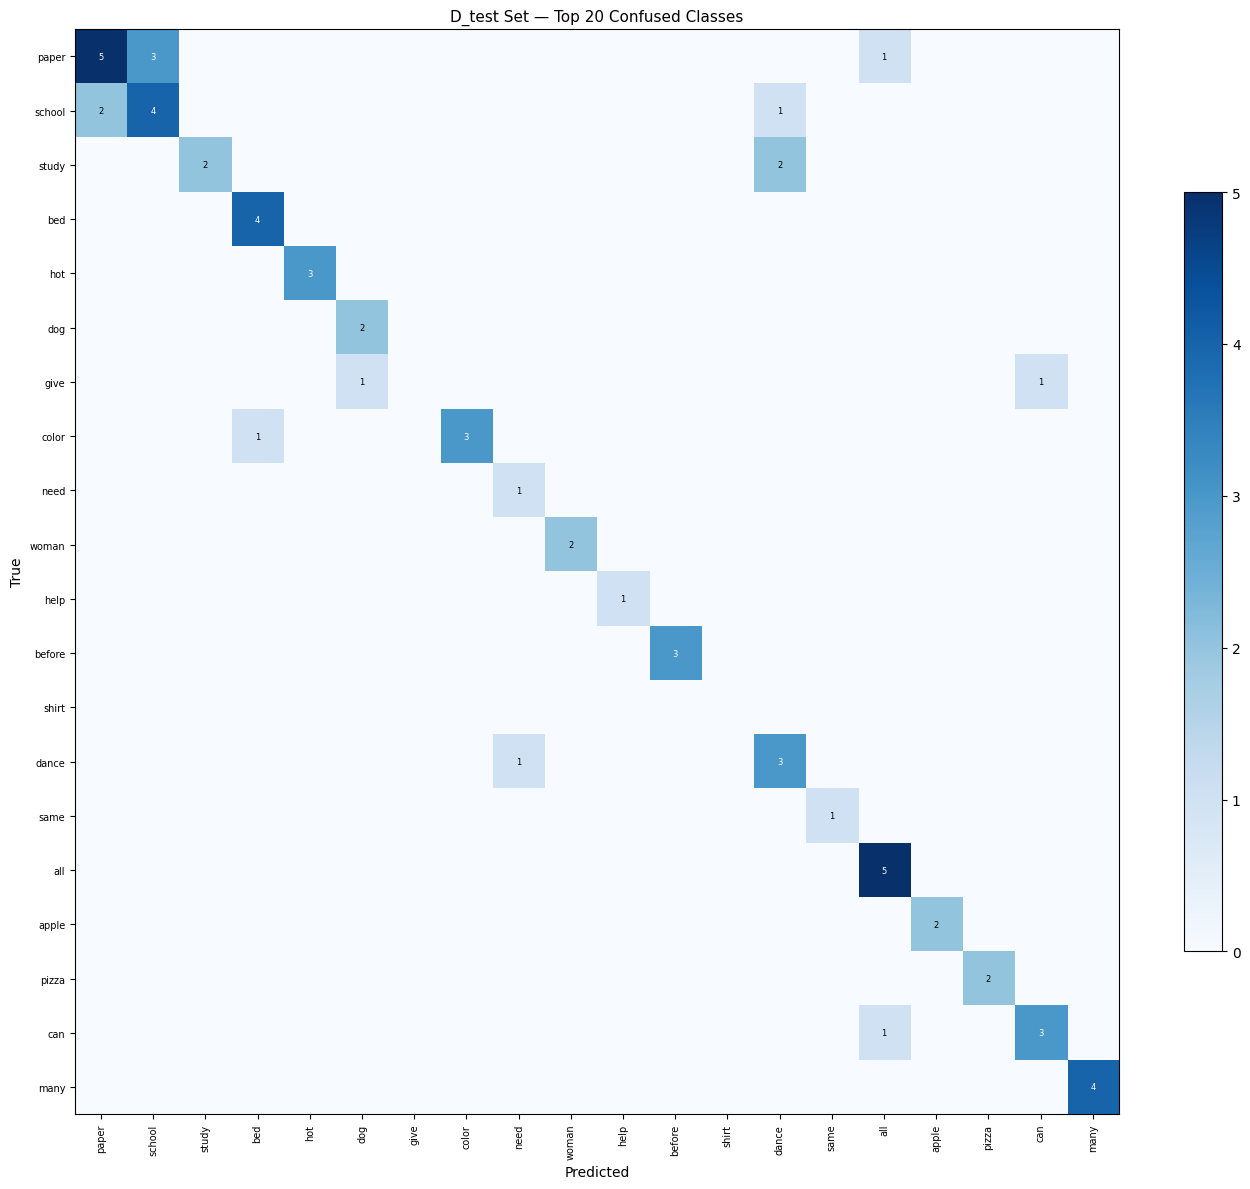


Top confusion pairs (D_test Set):
     3×  TRUE=paper                 PRED=school
     2×  TRUE=study                 PRED=dance
     2×  TRUE=school                PRED=paper
     2×  TRUE=hot                   PRED=orange
     2×  TRUE=dog                   PRED=bird
     1×  TRUE=woman                 PRED=want
     1×  TRUE=shirt                 PRED=man
     1×  TRUE=school                PRED=dance
     1×  TRUE=same                  PRED=walk
     1×  TRUE=pizza                 PRED=fine
     1×  TRUE=paper                 PRED=who
     1×  TRUE=paper                 PRED=all
     1×  TRUE=orange                PRED=apple
     1×  TRUE=now                   PRED=play
     1×  TRUE=need                  PRED=bird


In [31]:
# CELL 14C — Confusion Matrix Heatmap (top confusions) — SAFE VERSION

def plot_confusion_heatmap(y_true, y_pred, title="Confusion Matrix", top_n=20):
    """Show top-N most confused class pairs as a heatmap."""
    if y_true is None or y_pred is None:
        print(f"{title}: no data")
        return

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if len(y_true) == 0 or len(y_pred) == 0:
        print(f"{title}: no data")
        return

    if len(y_true) != len(y_pred):
        print(f"{title}: length mismatch — y_true={len(y_true)} y_pred={len(y_pred)}")
        return

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(num_classes))
    )

    # Remove diagonal to focus only on mistakes
    cm_no_diag = cm.copy()
    np.fill_diagonal(cm_no_diag, 0)

    confused_sums = cm_no_diag.sum(axis=1)
    confused_ids = np.where(confused_sums > 0)[0]

    if len(confused_ids) == 0:
        print(f"{title}: no off-diagonal confusions found.")
        return

    top_ids = confused_ids[np.argsort(confused_sums[confused_ids])[-top_n:]][::-1]

    def class_name(i):
        if "id_to_label" in globals():
            return id_to_label[int(i)]
        if "official_words" in globals():
            return official_words[int(i)]
        return str(i)

    top_words = [class_name(i) for i in top_ids]
    sub_cm = cm[np.ix_(top_ids, top_ids)]

    fig, ax = plt.subplots(figsize=(14, 12))
    im = ax.imshow(sub_cm, cmap="Blues", aspect="auto")

    ax.set_xticks(range(len(top_ids)))
    ax.set_xticklabels(top_words, rotation=90, fontsize=7)

    ax.set_yticks(range(len(top_ids)))
    ax.set_yticklabels(top_words, fontsize=7)

    max_v = sub_cm.max() if sub_cm.size else 0

    for i in range(len(top_ids)):
        for j in range(len(top_ids)):
            v = sub_cm[i, j]
            if v > 0:
                ax.text(
                    j,
                    i,
                    str(v),
                    ha="center",
                    va="center",
                    fontsize=6,
                    color="white" if max_v > 0 and v > max_v * 0.5 else "black",
                )

    ax.set_title(f"{title} — Top {len(top_ids)} Confused Classes", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

    plt.colorbar(im, ax=ax, shrink=0.7)
    plt.tight_layout()
    plt.show()

    # Print worst confusion pairs globally, not only inside submatrix
    pairs = []

    for true_i in range(num_classes):
        for pred_j in range(num_classes):
            if true_i != pred_j and cm[true_i, pred_j] > 0:
                pairs.append(
                    (
                        int(cm[true_i, pred_j]),
                        class_name(true_i),
                        class_name(pred_j),
                    )
                )

    pairs.sort(reverse=True)

    print(f"\nTop confusion pairs ({title}):")

    if not pairs:
        print("  No confusion pairs.")
    else:
        for cnt, true_w, pred_w in pairs[:15]:
            print(f"  {cnt:4d}×  TRUE={true_w:20s}  PRED={pred_w}")


# ─────────────────────────────────────────────────────────────
# Safe auto-detect available test prediction variables
# ─────────────────────────────────────────────────────────────

if "yt_test" in globals() and "yp_test" in globals():
    plot_confusion_heatmap(yt_test, yp_test, "Test Set")

elif "y_test" in globals() and "yp_test" in globals():
    plot_confusion_heatmap(y_test, yp_test, "Test Set")

elif "yt_dtest" in globals() and "yp_dtest" in globals():
    plot_confusion_heatmap(yt_dtest, yp_dtest, "D_test Set")

elif "y_d_test" in globals() and "yp_dtest" in globals():
    plot_confusion_heatmap(y_d_test, yp_dtest, "D_test Set")

else:
    print("Confusion heatmap skipped.")
    print("Reason: prediction variables are not defined yet.")
    print()
    print("Run the evaluation cell first, then run this cell again.")
    print()
    print("Expected one of these pairs:")
    print("  yt_test + yp_test")
    print("  y_test  + yp_test")
    print("  yt_dtest + yp_dtest")
    print("  y_d_test + yp_dtest")

In [32]:
# CELL 14D — v26 NEW: Confidence Calibration Report (ECE)
@torch.no_grad()
def calibration_report(model, X, y, name="split", n_bins=15):
    """
    Expected Calibration Error (ECE): measures how well confidence = accuracy.
    Lower ECE = better calibrated model. Good models: ECE < 5%.
    """
    if len(y) == 0: print(f"{name}: empty"); return
    device = next(model.parameters()).device
    ld = DataLoader(SignDataset(X, y, augment=False), batch_size=64, num_workers=0)
    model.eval()
    confs, corrects = [], []
    for xb, yb in ld:
        xb, yb = xb.to(device), yb.to(device)
        with torch.amp.autocast("cuda", enabled=(device.type=="cuda")):
            probs = torch.softmax(model(xb), dim=1)
        conf, pred = probs.max(1)
        corrects.extend((pred == yb).cpu().float().tolist())
        confs.extend(conf.cpu().tolist())
    confs    = np.array(confs)
    corrects = np.array(corrects)
    bins     = np.linspace(0, 1, n_bins + 1)
    ece      = 0.0
    print(f"\n=== Calibration Report: {name} ===")
    print(f"{'Bin':20s} | {'Acc':>6s} | {'Conf':>6s} | {'n':>5s} | {'|Acc-Conf|':>10s}")
    for i in range(n_bins):
        mask = (confs > bins[i]) & (confs <= bins[i+1])
        n = mask.sum()
        if n == 0: continue
        acc  = corrects[mask].mean()
        conf = confs[mask].mean()
        diff = abs(acc - conf)
        ece += diff * n / len(confs)
        bar  = "█" * int(diff * 30)
        print(f"  ({bins[i]:.2f}-{bins[i+1]:.2f}]   | {acc:6.3f} | {conf:6.3f} | {n:5d} | {diff:10.3f} {bar}")
    print(f"\n  ECE = {ece:.4f} ({ece*100:.2f}%) — {'✓ Well calibrated' if ece < 0.05 else '⚠️ Consider temperature scaling'}")
    return ece


calibration_report(model, X_val, y_val, "Combined_val")



=== Calibration Report: Combined_val ===
Bin                  |    Acc |   Conf |     n | |Acc-Conf|
  (0.07-0.13]   |  0.500 |  0.120 |     2 |      0.380 ███████████
  (0.13-0.20]   |  0.250 |  0.181 |     4 |      0.069 ██
  (0.20-0.27]   |  0.000 |  0.240 |     3 |      0.240 ███████
  (0.27-0.33]   |  0.500 |  0.300 |     4 |      0.200 █████
  (0.33-0.40]   |  0.312 |  0.367 |    16 |      0.055 █
  (0.40-0.47]   |  0.700 |  0.432 |    10 |      0.268 ████████
  (0.47-0.53]   |  0.538 |  0.488 |    13 |      0.050 █
  (0.53-0.60]   |  0.500 |  0.571 |     4 |      0.071 ██
  (0.60-0.67]   |  0.615 |  0.633 |    13 |      0.017 
  (0.67-0.73]   |  0.647 |  0.707 |    17 |      0.060 █
  (0.73-0.80]   |  0.889 |  0.772 |    27 |      0.117 ███
  (0.80-0.87]   |  0.904 |  0.840 |    52 |      0.064 █
  (0.87-0.93]   |  0.958 |  0.895 |    95 |      0.063 █
  (0.93-1.00]   |  1.000 |  0.946 |    14 |      0.054 █

  ECE = 0.0784 (7.84%) — ⚠️ Consider temperature scaling


np.float64(0.07844185179276186)

In [33]:
# CELL 15 — Predict on Video (v26: TTA×5)
def predict_video(video_path, top_k=5, use_tta=True, flip=FLIP_TEST, visualize=True):
    device = next(model.parameters()).device
    cap    = cv2.VideoCapture(video_path)
    seq    = []
    n0 = n1 = n2 = fi = 0
    preview_frames = []

    while True:
        ok, frame = cap.read()
        if not ok: break
        h, w = frame.shape[:2]
        if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
        if fi % SAMPLE_EVERY == 0:
            sk = frame_to_skeleton_v13(frame, flip_hands=flip)
            seq.append(sk)
            if fi < 5: preview_frames.append((frame.copy(), sk))
            n = int(np.abs(sk[:21]).sum()>1e-4) + int(np.abs(sk[21:42]).sum()>1e-4)
            if n==0: n0+=1
            elif n==1: n1+=1
            else: n2+=1
        fi += 1
    cap.release()

    if not seq: print("No frames extracted"); return None, 0.0

    total_f  = len(seq)
    zero_pct = n0 / total_f
    print(f"Frames: {total_f} | 0-hand: {n0}({zero_pct:.0%}) 1-hand: {n1} 2-hand: {n2}")
    if zero_pct > 0.5:
        print("  ⚠️  >50% zero-hand → try predict_video(path, flip=True)")

    if visualize and preview_frames:
        fig, axes = plt.subplots(1, len(preview_frames), figsize=(4*len(preview_frames), 3))
        if len(preview_frames) == 1: axes = [axes]
        for ai, (frm, sk) in enumerate(preview_frames):
            ann = draw_skeleton(frm, sk, word="predict", frame_idx=ai)
            axes[ai].imshow(cv2.cvtColor(ann, cv2.COLOR_BGR2RGB))
            axes[ai].axis("off"); axes[ai].set_title(f"f{ai}")
        plt.suptitle("First 5 frames entering the model", fontsize=10)
        plt.tight_layout(); plt.show()

    seq    = np.array(seq, dtype=np.float32)
    tensor = fix_tensor_length(to_stgcn_tensor(seq))          # (6, 64, 57, 1)
    X_np   = np.transpose(tensor[None], (0, 4, 1, 2, 3))      # (1, 1, 6, 64, 57)
    X_t    = torch.tensor(X_np, dtype=torch.float32).to(device)

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(X_t), dim=1)
        if use_tta:
            augmented_inputs = []
            # TTA 1: horizontal flip (x-coord and x-velocity)
            Xm = X_np.copy()
            Xm[:,:,0,:,:] = -Xm[:,:,0,:,:]
            Xm[:,:,3,:,:] = -Xm[:,:,3,:,:]
            augmented_inputs.append(Xm)
            # TTA 2: time shift +2 frames
            augmented_inputs.append(np.roll(X_np, 2, axis=3))
            # TTA 3: time shift -2 frames
            augmented_inputs.append(np.roll(X_np, -2, axis=3))
            # TTA 4: time stretch 0.9 (compress to 90% of frames, pad with last)
            T = X_np.shape[3]
            idx_stretch = np.round(np.linspace(0, T*0.9-1, T)).astype(int).clip(0, T-1)
            Xs = X_np[:, :, :, idx_stretch, :]
            augmented_inputs.append(Xs)
            # Average all TTA predictions
            for aug_x in augmented_inputs:
                aug_t = torch.tensor(aug_x, dtype=torch.float32).to(device)
                probs = probs + torch.softmax(model(aug_t), dim=1)
            probs = probs / (1 + len(augmented_inputs))

        topk = probs[0].topk(min(top_k, num_classes))

    tta_str = f"[TTA×{1+len(augmented_inputs) if use_tta else 1}]" if use_tta else ""
    print(f"\nPredictions{tta_str}:")
    for prob, idx in zip(topk.values, topk.indices):
        w  = official_words[idx.item()]
        jt = "[POSE]" if w in POSE_WORDS else "[HAND]"
        bar = "█" * int(float(prob) * 30)
        conf_warn = " ⚠️low" if float(prob) < 0.15 else ""
        print(f"  {w:22s} {jt}  {float(prob):.1%}  {bar}{conf_warn}")

    top_word = official_words[topk.indices[0].item()]
    top_conf = float(topk.values[0])
    return top_word, top_conf


print("predict_video() defined ✓ (v26 — TTA×5)")


predict_video() defined ✓ (v26 — TTA×5)


Testing: 'drink' [POSE] | 3 videos

--- 17709 ---
Visualizing: 17709.mp4 | flip=False
  Frames: 30 | 0-hand: 24 (80%) | 1-hand: 6 | 2-hand: 0
  ⚠️  >50% zero dominant → try flip=True
  Saved: H:\Graduation project\outputs_v27_top60\viz_17709_flipFalse.mp4
Frames: 105 | 0-hand: 65(62%) 1-hand: 40 2-hand: 0
  ⚠️  >50% zero-hand → try predict_video(path, flip=True)


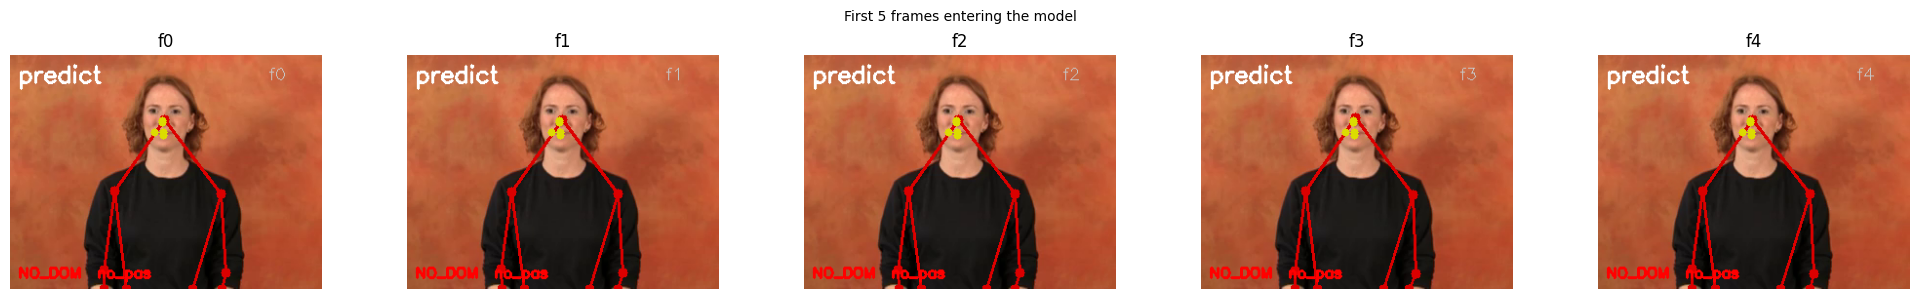


Predictions[TTA×5]:
  drink                  [POSE]  73.2%  █████████████████████
  color                  [POSE]  17.4%  █████
  orange                 [POSE]  0.3%   ⚠️low
Result: drink (73.2%) ✓

--- 17710 ---
Visualizing: 17710.mp4 | flip=False
  Frames: 30 | 0-hand: 10 (33%) | 1-hand: 20 | 2-hand: 0
  ⚠️  >30% zero-hand — check video quality/orientation
  Saved: H:\Graduation project\outputs_v27_top60\viz_17710_flipFalse.mp4
Frames: 70 | 0-hand: 36(51%) 1-hand: 34 2-hand: 0
  ⚠️  >50% zero-hand → try predict_video(path, flip=True)


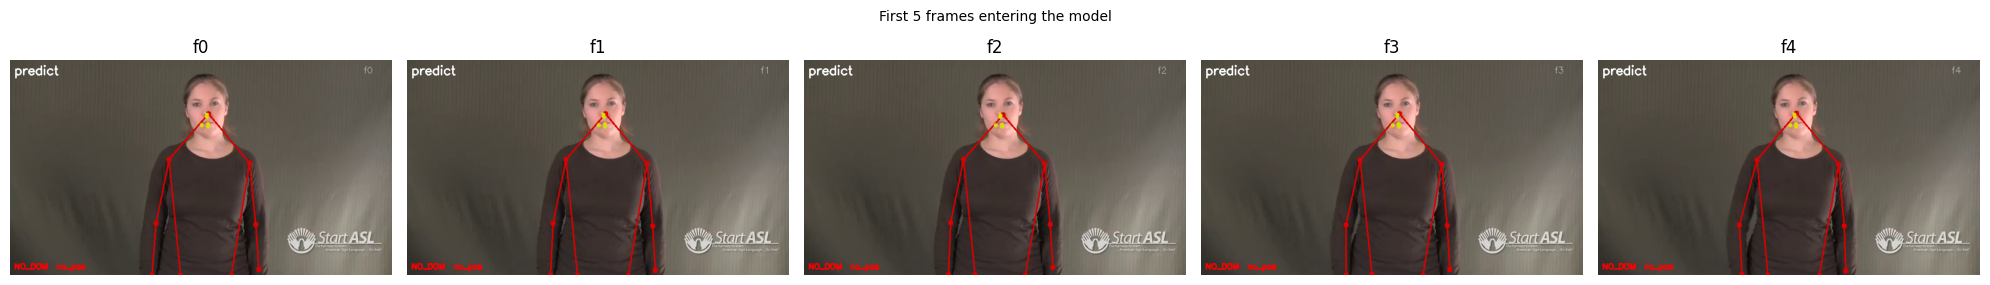


Predictions[TTA×5]:
  drink                  [POSE]  67.1%  ████████████████████
  bed                    [POSE]  11.4%  ███ ⚠️low
  brown                  [POSE]  2.0%   ⚠️low
Result: drink (67.1%) ✓

--- 17711 ---
Visualizing: 17711.mp4 | flip=False
  Frames: 30 | 0-hand: 20 (67%) | 1-hand: 10 | 2-hand: 0
  ⚠️  >50% zero dominant → try flip=True
  Saved: H:\Graduation project\outputs_v27_top60\viz_17711_flipFalse.mp4
Frames: 81 | 0-hand: 45(56%) 1-hand: 36 2-hand: 0
  ⚠️  >50% zero-hand → try predict_video(path, flip=True)


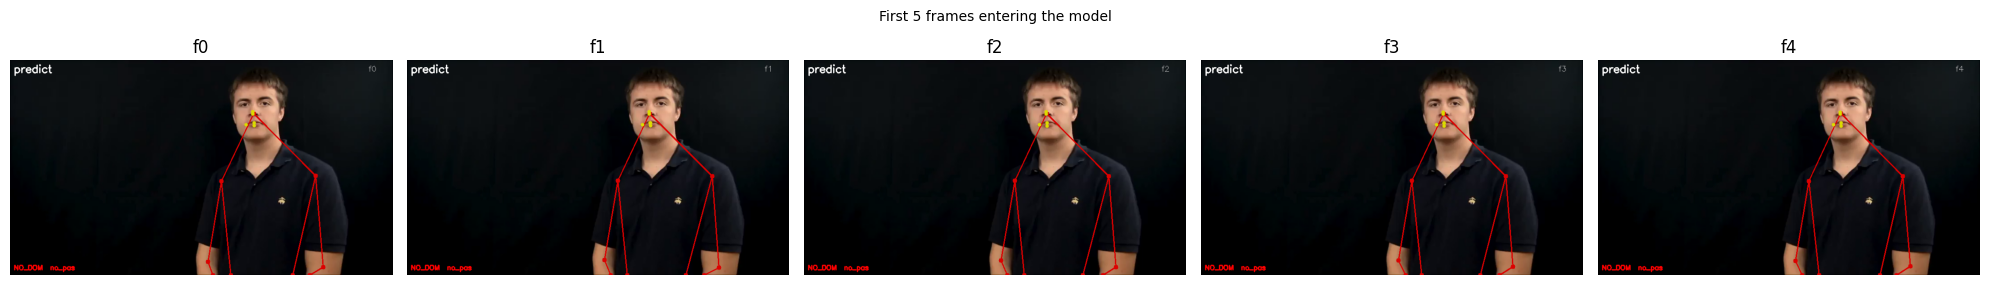


Predictions[TTA×5]:
  drink                  [POSE]  76.4%  ██████████████████████
  blue                   [HAND]  11.3%  ███ ⚠️low
  many                   [HAND]  0.7%   ⚠️low
Result: drink (76.4%) ✓


In [34]:
# CELL 16 — Debug on Known Videos
DRIVE = str(OUTPUT_DIR)  # alias for compatibility

import os, json, traceback
from pathlib import Path

TEST_WORD  = "drink"
MAX_VIDEOS = 3
WLASL_VIDEOS_DIR_P = Path(WLASL_VIDEOS_DIR)

if "video_to_label" not in dir():
    with open(SAMPLES_JSON_PATH, "r", encoding="utf-8") as f:
        s = json.load(f)
    video_to_label = {}
    for item in s["samples"]:
        g = item["gloss"]
        if isinstance(g, dict): g = g["label"]
        vid_key = Path(item["filepath"]).stem
        video_to_label[vid_key] = g

test_vids = [v for v, l in video_to_label.items() if l == TEST_WORD][:MAX_VIDEOS]
jtype = "POSE" if TEST_WORD in POSE_WORDS else "HAND_ONLY"
print(f"Testing: '{TEST_WORD}' [{jtype}] | {len(test_vids)} videos")

for vid_id in test_vids:
    vpath = WLASL_VIDEOS_DIR_P / f"{vid_id}.mp4"
    if not vpath.exists():
        print(f"Not found: {vpath}"); continue
    print(f"\n--- {vid_id} ---")
    try:
        stats = visualize_video(str(vpath), max_frames=30, word=TEST_WORD)
        flip  = stats.get("zero_pct", 0) > 0.5
        pred, conf = predict_video(str(vpath), top_k=3, flip=flip, visualize=True)
        if pred:
            ok = "✓" if pred == TEST_WORD else "✗"
            print(f"Result: {pred} ({conf:.1%}) {ok}")
    except Exception as e:
        print(f"ERROR: {type(e).__name__}: {e}")
        traceback.print_exc()


Original video: C:/Users/ce/Downloads/YTDown_YouTube_PAPER_Media_Zg7-DM25KIM_001_1080p.mp4
Saved rotated video: H:\Graduation project\outputs_v27_top60\YTDown_YouTube_PAPER_Media_Zg7-DM25KIM_001_1080p_angle90.mp4

Using video: H:\Graduation project\outputs_v27_top60\YTDown_YouTube_PAPER_Media_Zg7-DM25KIM_001_1080p_angle90.mp4
Visualizing: YTDown_YouTube_PAPER_Media_Zg7-DM25KIM_001_1080p_angle90.mp4 | flip=False
  Frames: 60 | 0-hand: 18 (30%) | 1-hand: 6 | 2-hand: 36
  ✓  Detection healthy
  Saved: H:\Graduation project\outputs_v27_top60\viz_YTDown_YouTube_PAPER_Media_Zg7-DM25KIM_001_1080p_angle90_flipFalse.mp4
Frames: 87 | 0-hand: 35(40%) 1-hand: 10 2-hand: 42


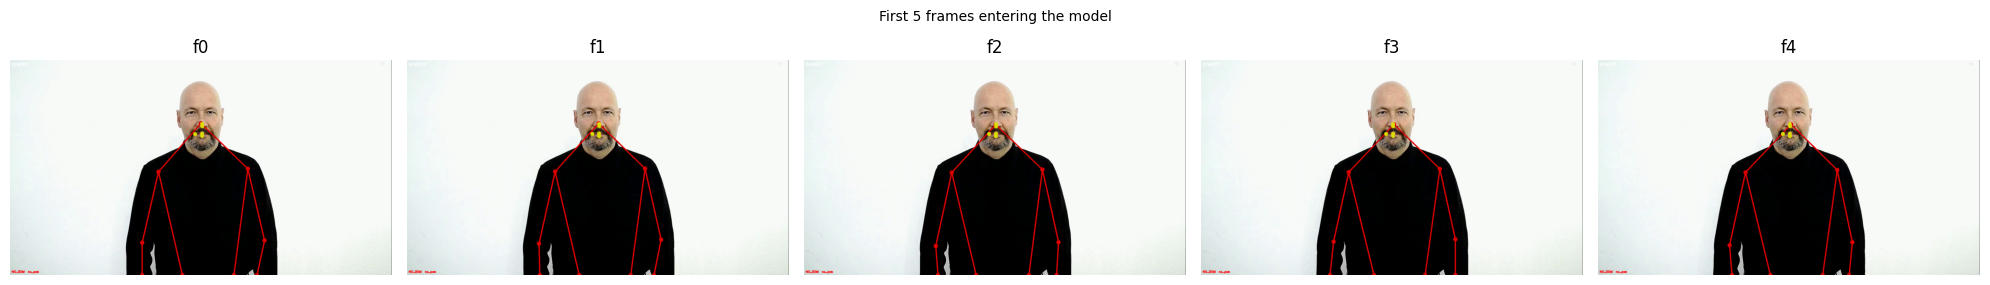


Predictions[TTA×5]:
  doctor                 [POSE]  60.7%  ██████████████████
  paper                  [HAND]  5.5%  █ ⚠️low
  birthday               [HAND]  5.2%  █ ⚠️low
  like                   [POSE]  2.8%   ⚠️low
  give                   [HAND]  1.2%   ⚠️low

→ doctor (60.7%) [POSE]


In [60]:
# CELL 17 — Predict New Video (with rotation fix)
import math
try:
    import tkinter as tk
    from tkinter import filedialog
    _has_tk = True
except ImportError:
    _has_tk = False

video_path = r""   # paste path here, or leave empty to open file dialog
ANGLE = 90       # try: -90, 90, 180, 0

if not video_path:
    if _has_tk:
        try:
            root = tk.Tk(); root.withdraw()
            root.attributes("-topmost", True)
            video_path = filedialog.askopenfilename(
                filetypes=[("Video", "*.mp4 *.avi *.mov *.mkv"),("All","*.*")])
            root.destroy()
        except:
            raise RuntimeError("Set video_path manually above")
    else:
        raise RuntimeError("Set video_path manually above (tkinter not available)")

if not video_path: raise RuntimeError("No video selected")
if not os.path.exists(video_path): raise FileNotFoundError(video_path)
print(f"Original video: {video_path}")


def rotate_bound(frame, angle):
    h, w   = frame.shape[:2]
    center = (w/2, h/2)
    M      = cv2.getRotationMatrix2D(center, angle, 1.0)
    cos, sin = abs(M[0,0]), abs(M[0,1])
    new_w  = int(h*sin + w*cos)
    new_h  = int(h*cos + w*sin)
    M[0,2] += new_w/2 - center[0]
    M[1,2] += new_h/2 - center[1]
    return cv2.warpAffine(frame, M, (new_w, new_h),
                          flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)


def fix_video_angle(in_path, out_dir, angle):
    os.makedirs(out_dir, exist_ok=True)
    cap = cv2.VideoCapture(in_path)
    if not cap.isOpened(): raise RuntimeError(f"Cannot open: {in_path}")
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    ret, first = cap.read()
    if not ret: cap.release(); raise RuntimeError("Cannot read first frame")
    ff   = rotate_bound(first, angle)
    h, w = ff.shape[:2]
    base = os.path.splitext(os.path.basename(in_path))[0]
    out  = os.path.join(out_dir, f"{base}_angle{angle}.mp4")
    wr   = cv2.VideoWriter(out, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    wr.write(ff)
    while True:
        ret, fr = cap.read()
        if not ret: break
        wr.write(rotate_bound(fr, angle))
    cap.release(); wr.release()
    print(f"Saved rotated video: {out}")
    return out


if ANGLE != 0:
    fixed_video = fix_video_angle(video_path, OUTPUT_DIR, ANGLE)
    video_path  = fixed_video
print(f"\nUsing video: {video_path}")

stats      = visualize_video(video_path, max_frames=60)
best_flip  = stats["zero_pct"] > 0.5
pred, conf = predict_video(video_path, top_k=5, flip=best_flip, use_tta=True, visualize=True)
if pred:
    jt = "POSE" if pred in POSE_WORDS else "HAND_ONLY"
    print(f"\n→ {pred} ({conf:.1%}) [{jt}]")


Original video: C:/Users/ce/Downloads/hearing wael.mp4
Original frames: 123
Saved prepared video: H:\Graduation project\outputs_v27_top60\hearing wael_prepared_angle0.mp4
Prepared frames     : 123


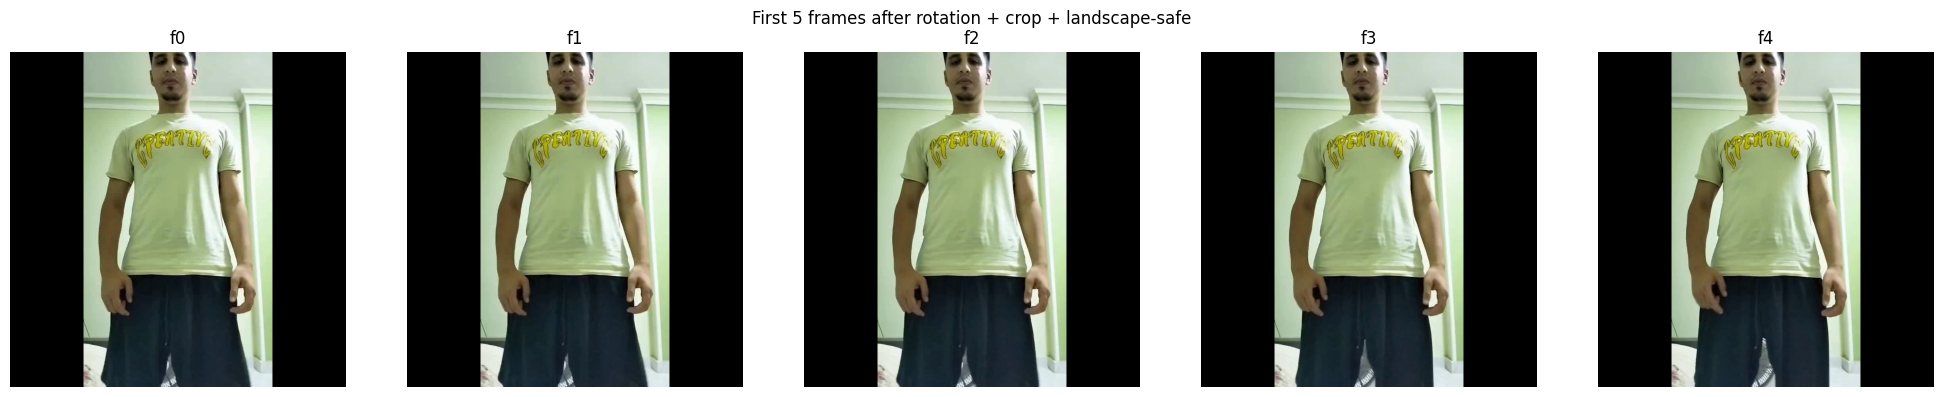

Frames before motion trim: 123
Motion trim window : 59 → 123
Frames after trim  : 64
Saved motion video : H:\Graduation project\outputs_v27_top60\hearing wael_prepared_angle0_motion_trim.mp4

Using video: H:\Graduation project\outputs_v27_top60\hearing wael_prepared_angle0_motion_trim.mp4


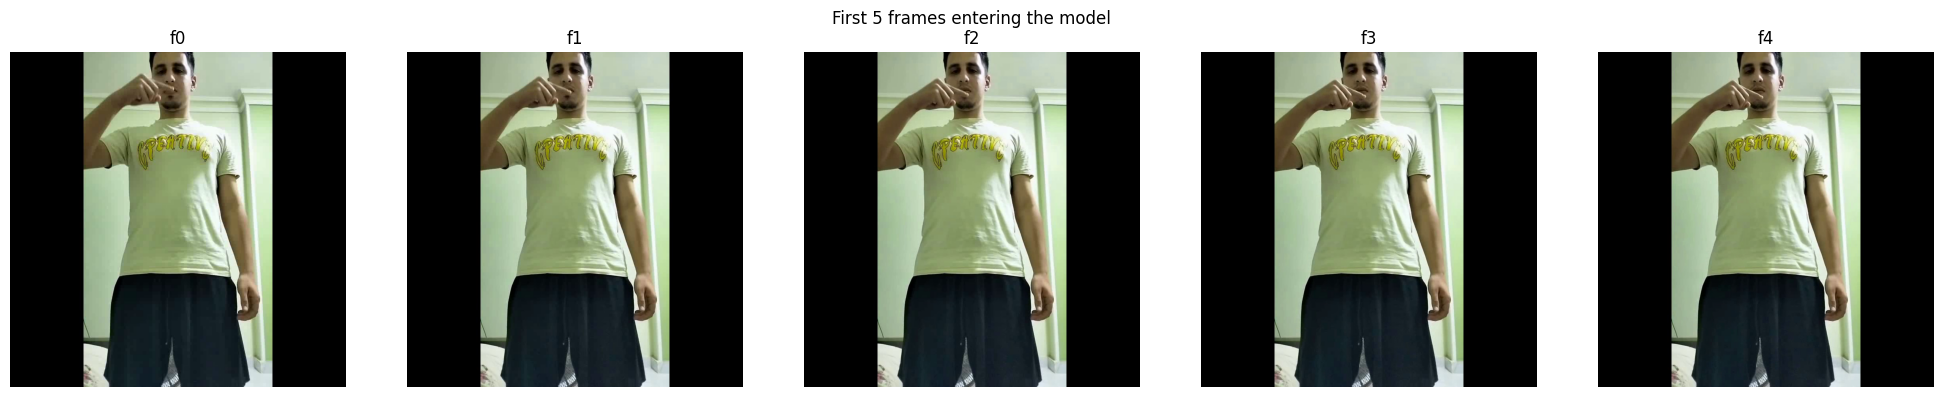

Visualizing: hearing wael_prepared_angle0_motion_trim.mp4 | flip=False
  Frames: 60 | 0-hand: 0 (0%) | 1-hand: 10 | 2-hand: 50
  ✓  Detection healthy
  Saved: H:\Graduation project\outputs_v27_top60\viz_hearing wael_prepared_angle0_motion_trim_flipFalse.mp4
Frames visualized: 60 | 0-hand: 0 (0%) | 1-hand: 10 | 2-hand: 50
Auto flip disabled
Frames: 64 | 0-hand: 0(0%) 1-hand: 11 2-hand: 53


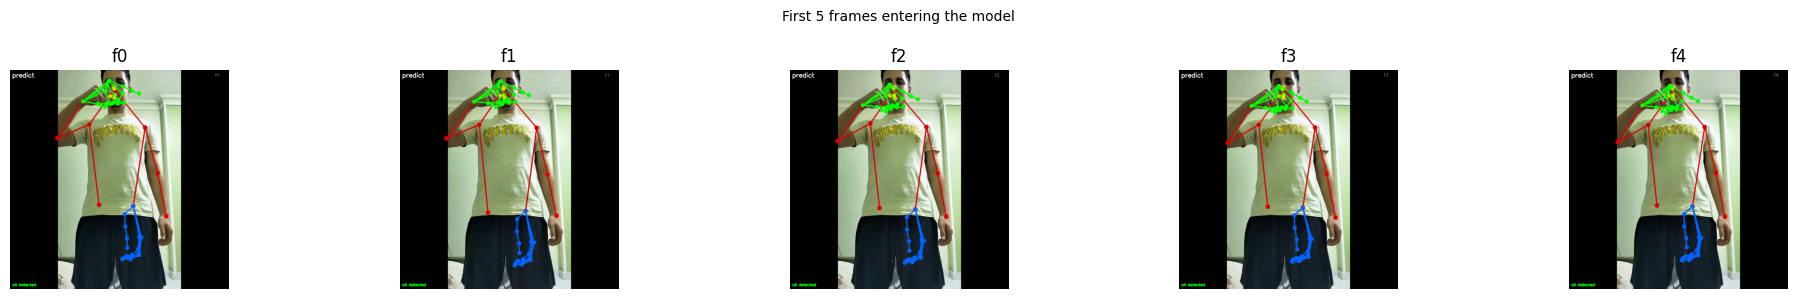


Predictions[TTA×5]:
  hearing                [POSE]  54.8%  ████████████████
  dog                    [HAND]  11.2%  ███ ⚠️low
  black                  [POSE]  4.9%  █ ⚠️low
  doctor                 [POSE]  4.1%  █ ⚠️low
  apple                  [POSE]  2.9%   ⚠️low

→ hearing (54.8%) [POSE]


In [111]:
# CELL 17 — Predict New Video (rotation + crop + landscape-safe + motion trim)

import os, cv2, math
import numpy as np
import matplotlib.pyplot as plt

try:
    import tkinter as tk
    from tkinter import filedialog
    _has_tk = True
except ImportError:
    _has_tk = False


# ─────────────────────────────────────────────────────────────
# Settings
# ─────────────────────────────────────────────────────────────
video_path = r""     # paste path here, or leave empty to open file dialog

ANGLE = 0           # try: 0, 90, -90, 180, 30, -30
USE_MOTION_TRIM = True
MOTION_WINDOW = TARGET_FRAMES   # normally 64
MAX_VIS_FRAMES = 60


# ─────────────────────────────────────────────────────────────
# Pick video
# ─────────────────────────────────────────────────────────────
if not video_path:
    if _has_tk:
        try:
            root = tk.Tk()
            root.withdraw()
            root.attributes("-topmost", True)
            video_path = filedialog.askopenfilename(
                filetypes=[
                    ("Video", "*.mp4 *.avi *.mov *.mkv"),
                    ("All", "*.*"),
                ]
            )
            root.destroy()
        except Exception:
            raise RuntimeError("Set video_path manually above")
    else:
        raise RuntimeError("Set video_path manually above (tkinter not available)")

if not video_path:
    raise RuntimeError("No video selected")

if not os.path.exists(video_path):
    raise FileNotFoundError(video_path)

print(f"Original video: {video_path}")


# ─────────────────────────────────────────────────────────────
# Helpers
# ─────────────────────────────────────────────────────────────
def count_video_frames(path):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        return 0

    n = 0
    while True:
        ok, _ = cap.read()
        if not ok:
            break
        n += 1

    cap.release()
    return n


def rotate_bound(frame, angle):
    h, w = frame.shape[:2]
    center = (w / 2, h / 2)

    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    cos = abs(M[0, 0])
    sin = abs(M[0, 1])

    new_w = int(h * sin + w * cos)
    new_h = int(h * cos + w * sin)

    M[0, 2] += new_w / 2 - center[0]
    M[1, 2] += new_h / 2 - center[1]

    return cv2.warpAffine(
        frame,
        M,
        (new_w, new_h),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0),
    )


def crop_black_borders(frame, threshold=8, pad=8):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    mask = gray > threshold

    ys, xs = np.where(mask)

    if len(xs) == 0 or len(ys) == 0:
        return frame

    x1 = max(xs.min() - pad, 0)
    x2 = min(xs.max() + pad, frame.shape[1] - 1)
    y1 = max(ys.min() - pad, 0)
    y2 = min(ys.max() + pad, frame.shape[0] - 1)

    out = frame[y1:y2 + 1, x1:x2 + 1]

    if out.size == 0:
        return frame

    return out


def pad_to_landscape_frame(frame, bg_color=(0, 0, 0)):
    """
    Makes width >= height.
    This prevents old code inside visualize_video / predict_video from doing:
    if h > w: rotate 90
    """
    h, w = frame.shape[:2]

    if w >= h:
        return frame

    new_w = h
    pad_left = (new_w - w) // 2
    pad_right = new_w - w - pad_left

    return cv2.copyMakeBorder(
        frame,
        0,
        0,
        pad_left,
        pad_right,
        cv2.BORDER_CONSTANT,
        value=bg_color,
    )


def save_prepared_video(in_path, out_dir, angle):
    """
    1) rotate
    2) crop black borders
    3) pad to landscape
    4) save fixed video
    """
    os.makedirs(out_dir, exist_ok=True)

    cap = cv2.VideoCapture(in_path)
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open: {in_path}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    frames = []

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        if angle != 0:
            frame = rotate_bound(frame, angle)
            frame = crop_black_borders(frame)

        frame = pad_to_landscape_frame(frame)

        if frame.shape[0] < 32 or frame.shape[1] < 32:
            continue

        frames.append(frame)

    cap.release()

    if not frames:
        raise RuntimeError("No frames read from video")

    max_h = max(f.shape[0] for f in frames)
    max_w = max(f.shape[1] for f in frames)

    fixed_frames = []
    for f in frames:
        fixed_frames.append(cv2.resize(f, (max_w, max_h), interpolation=cv2.INTER_LINEAR))

    base = os.path.splitext(os.path.basename(in_path))[0]
    safe_angle = str(angle).replace("-", "m")
    out_path = os.path.join(out_dir, f"{base}_prepared_angle{safe_angle}.mp4")

    writer = cv2.VideoWriter(
        out_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (max_w, max_h),
    )

    for f in fixed_frames:
        writer.write(f)

    writer.release()

    print(f"Saved prepared video: {out_path}")
    print(f"Prepared frames     : {len(fixed_frames)}")

    return out_path


def preview_video_frames(path, title="First 5 frames", max_frames=5):
    cap = cv2.VideoCapture(path)
    frames = []

    while len(frames) < max_frames:
        ok, frame = cap.read()
        if not ok:
            break

        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    cap.release()

    if not frames:
        print("No frames to preview.")
        return

    plt.figure(figsize=(4 * len(frames), 4))

    for i, fr in enumerate(frames):
        plt.subplot(1, len(frames), i + 1)
        plt.imshow(fr)
        plt.title(f"f{i}")
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


def trim_video_to_motion(in_path, out_dir, window=64):
    """
    Keeps the most active part of the video using pixel motion.
    If the video is shorter than window, it keeps the whole video.
    """
    cap = cv2.VideoCapture(in_path)
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open: {in_path}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    frames = []
    grays = []

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        frames.append(frame)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.resize(gray, (160, 160), interpolation=cv2.INTER_AREA)
        grays.append(gray.astype(np.float32))

    cap.release()

    n = len(frames)

    if n == 0:
        raise RuntimeError("No frames for motion trim")

    print(f"Frames before motion trim: {n}")

    if n <= window:
        print("Motion trim skipped: video shorter than/equal to target window")
        return in_path

    motion = np.zeros(n, dtype=np.float32)

    for i in range(1, n):
        motion[i] = np.mean(np.abs(grays[i] - grays[i - 1]))

    # Smooth motion
    k = 5
    kernel = np.ones(k, dtype=np.float32) / k
    motion_smooth = np.convolve(motion, kernel, mode="same")

    scores = np.convolve(motion_smooth, np.ones(window, dtype=np.float32), mode="valid")
    start = int(np.argmax(scores))
    end = start + window

    trimmed = frames[start:end]

    base = os.path.splitext(os.path.basename(in_path))[0]
    out_path = os.path.join(out_dir, f"{base}_motion_trim.mp4")

    h, w = trimmed[0].shape[:2]

    writer = cv2.VideoWriter(
        out_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (w, h),
    )

    for f in trimmed:
        writer.write(f)

    writer.release()

    print(f"Motion trim window : {start} → {end}")
    print(f"Frames after trim  : {len(trimmed)}")
    print(f"Saved motion video : {out_path}")

    return out_path


# ─────────────────────────────────────────────────────────────
# Prepare video
# ─────────────────────────────────────────────────────────────
original_frames = count_video_frames(video_path)
print(f"Original frames: {original_frames}")

prepared_video = save_prepared_video(
    video_path,
    OUTPUT_DIR,
    ANGLE,
)

preview_video_frames(
    prepared_video,
    title="First 5 frames after rotation + crop + landscape-safe"
)

if USE_MOTION_TRIM:
    final_video = trim_video_to_motion(
        prepared_video,
        OUTPUT_DIR,
        window=MOTION_WINDOW,
    )
else:
    final_video = prepared_video

print(f"\nUsing video: {final_video}")

preview_video_frames(
    final_video,
    title="First 5 frames entering the model"
)


# ─────────────────────────────────────────────────────────────
# Visualize landmarks
# ─────────────────────────────────────────────────────────────
stats = visualize_video(
    final_video,
    max_frames=MAX_VIS_FRAMES,
    flip=False,
)

print(
    f"Frames visualized: {stats['n_frames']} | "
    f"0-hand: {stats['n0']} ({stats['zero_pct']:.0%}) | "
    f"1-hand: {stats['n1']} | "
    f"2-hand: {stats['n2']}"
)

best_flip = stats["zero_pct"] > 0.5

if best_flip:
    print("Auto flip enabled because zero-hand rate > 50%")
else:
    print("Auto flip disabled")


# ─────────────────────────────────────────────────────────────
# Predict
# ─────────────────────────────────────────────────────────────
pred, conf = predict_video(
    final_video,
    top_k=5,
    flip=best_flip,
    use_tta=True,
    visualize=True,
)

if pred:
    jt = "POSE" if pred in POSE_WORDS else "HAND_ONLY"
    print(f"\n→ {pred} ({conf:.1%}) [{jt}]")
else:
    print("\nNo prediction returned.")

Original video: C:/Users/ce/Downloads/need bavely.mp4
Original frames: 148
Saved prepared video: H:\Graduation project\outputs_v27_top60\need bavely_prepared_angle0.mp4
Prepared frames     : 148


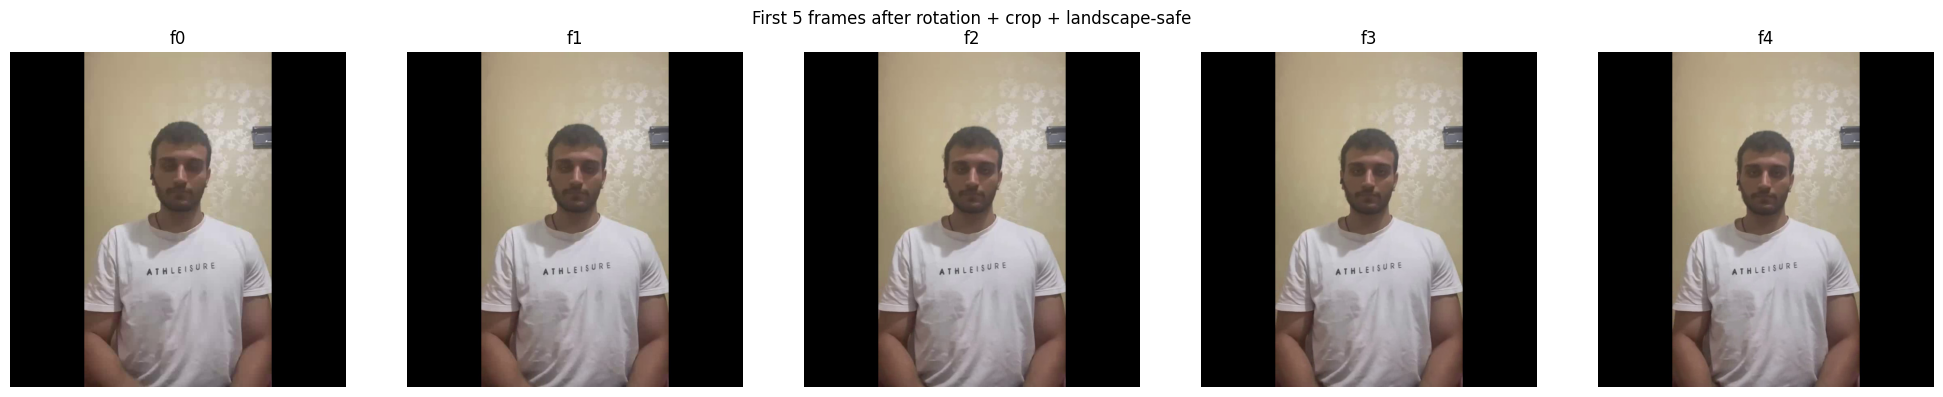

Frames before motion trim: 148
Motion trim window : 1 → 65
Frames after trim  : 64
Saved motion video : H:\Graduation project\outputs_v27_top60\need bavely_prepared_angle0_motion_trim.mp4

Using video: H:\Graduation project\outputs_v27_top60\need bavely_prepared_angle0_motion_trim.mp4


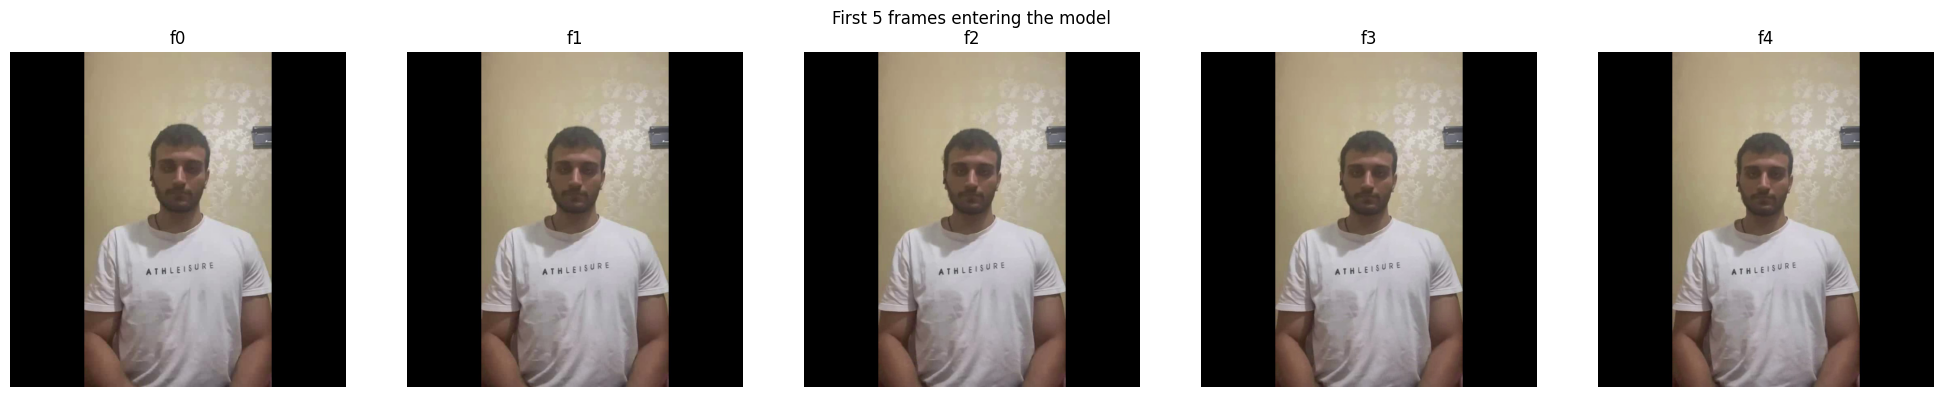

Visualizing: need bavely_prepared_angle0_motion_trim.mp4 | flip=False
  Frames: 60 | 0-hand: 44 (73%) | 1-hand: 16 | 2-hand: 0
  ⚠️  >50% zero dominant → try flip=True
  Saved: H:\Graduation project\outputs_v27_top60\viz_need bavely_prepared_angle0_motion_trim_flipFalse.mp4
Frames visualized: 60 | 0-hand: 44 (73%) | 1-hand: 16 | 2-hand: 0

Zero-hand rate: 73%
⚠️ High zero-hand rate >30% — testing both flip=False and flip=True

Prediction with flip=False
Frames: 64 | 0-hand: 44(69%) 1-hand: 20 2-hand: 0
  ⚠️  >50% zero-hand → try predict_video(path, flip=True)


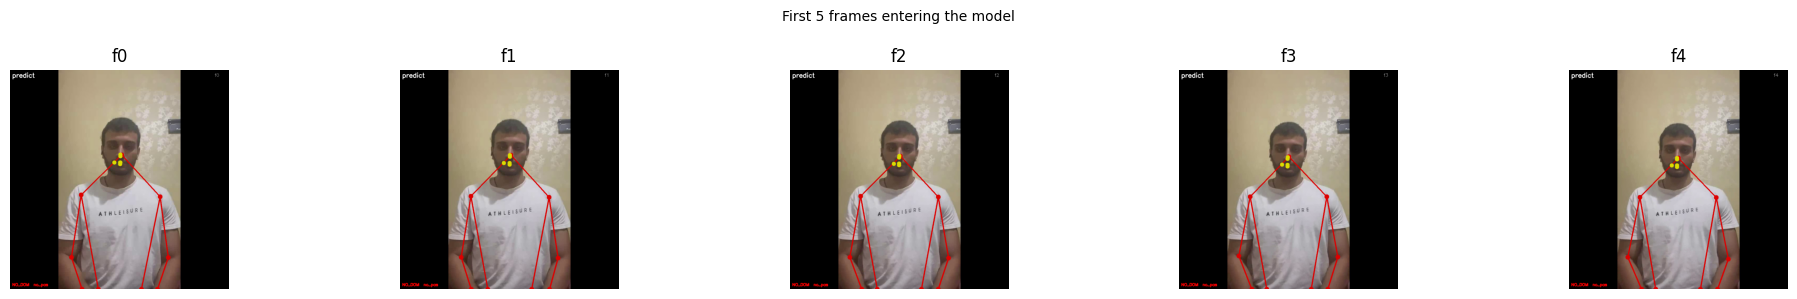


Predictions[TTA×5]:
  bird                   [HAND]  22.6%  ██████
  time                   [POSE]  5.9%  █ ⚠️low
  who                    [POSE]  5.4%  █ ⚠️low
  pizza                  [POSE]  4.6%  █ ⚠️low
  later                  [HAND]  4.3%  █ ⚠️low

→ bird (22.6%) [HAND_ONLY] | flip=False

Prediction with flip=True
Frames: 64 | 0-hand: 44(69%) 1-hand: 20 2-hand: 0
  ⚠️  >50% zero-hand → try predict_video(path, flip=True)


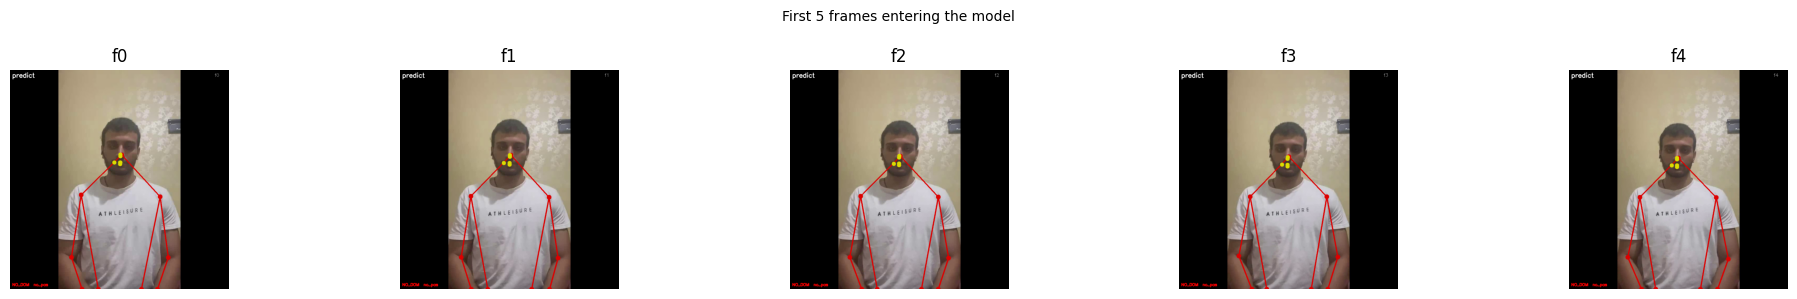


Predictions[TTA×5]:
  bird                   [HAND]  25.1%  ███████
  time                   [POSE]  7.0%  ██ ⚠️low
  later                  [HAND]  4.4%  █ ⚠️low
  pizza                  [POSE]  4.0%  █ ⚠️low
  who                    [POSE]  3.7%  █ ⚠️low

→ bird (25.1%) [HAND_ONLY] | flip=True

FINAL SUMMARY
flip=True: bird            | 25.1% | HAND_ONLY
flip=False: bird            | 22.6% | HAND_ONLY

BEST:
→ bird (25.1%) [HAND_ONLY] | flip=True


In [114]:
# CELL 17 — Predict New Video (rotation + crop + landscape-safe + motion trim + flip search)

import os, cv2, math
import numpy as np
import matplotlib.pyplot as plt

try:
    import tkinter as tk
    from tkinter import filedialog
    _has_tk = True
except ImportError:
    _has_tk = False


# ─────────────────────────────────────────────────────────────
# Settings
# ─────────────────────────────────────────────────────────────
video_path = r""     # paste path here, or leave empty to open file dialog

ANGLE = 0            # try: 0, 90, -90, 180, 30, -30
USE_MOTION_TRIM = True
MOTION_WINDOW = TARGET_FRAMES   # normally 64
MAX_VIS_FRAMES = 60


# ─────────────────────────────────────────────────────────────
# Pick video
# ─────────────────────────────────────────────────────────────
if not video_path:
    if _has_tk:
        try:
            root = tk.Tk()
            root.withdraw()
            root.attributes("-topmost", True)
            video_path = filedialog.askopenfilename(
                filetypes=[
                    ("Video", "*.mp4 *.avi *.mov *.mkv"),
                    ("All", "*.*"),
                ]
            )
            root.destroy()
        except Exception:
            raise RuntimeError("Set video_path manually above")
    else:
        raise RuntimeError("Set video_path manually above (tkinter not available)")

if not video_path:
    raise RuntimeError("No video selected")

if not os.path.exists(video_path):
    raise FileNotFoundError(video_path)

print(f"Original video: {video_path}")


# ─────────────────────────────────────────────────────────────
# Helpers
# ─────────────────────────────────────────────────────────────
def count_video_frames(path):
    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        return 0

    n = 0

    while True:
        ok, _ = cap.read()

        if not ok:
            break

        n += 1

    cap.release()

    return n


def rotate_bound(frame, angle):
    h, w = frame.shape[:2]
    center = (w / 2, h / 2)

    M = cv2.getRotationMatrix2D(center, angle, 1.0)

    cos = abs(M[0, 0])
    sin = abs(M[0, 1])

    new_w = int(h * sin + w * cos)
    new_h = int(h * cos + w * sin)

    M[0, 2] += new_w / 2 - center[0]
    M[1, 2] += new_h / 2 - center[1]

    return cv2.warpAffine(
        frame,
        M,
        (new_w, new_h),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0),
    )


def crop_black_borders(frame, threshold=8, pad=8):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    mask = gray > threshold

    ys, xs = np.where(mask)

    if len(xs) == 0 or len(ys) == 0:
        return frame

    x1 = max(xs.min() - pad, 0)
    x2 = min(xs.max() + pad, frame.shape[1] - 1)
    y1 = max(ys.min() - pad, 0)
    y2 = min(ys.max() + pad, frame.shape[0] - 1)

    out = frame[y1:y2 + 1, x1:x2 + 1]

    if out.size == 0:
        return frame

    return out


def pad_to_landscape_frame(frame, bg_color=(0, 0, 0)):
    """
    Makes width >= height.
    This prevents old code inside visualize_video / predict_video from doing:
    if h > w: rotate 90
    """
    h, w = frame.shape[:2]

    if w >= h:
        return frame

    new_w = h
    pad_left = (new_w - w) // 2
    pad_right = new_w - w - pad_left

    return cv2.copyMakeBorder(
        frame,
        0,
        0,
        pad_left,
        pad_right,
        cv2.BORDER_CONSTANT,
        value=bg_color,
    )


def save_prepared_video(in_path, out_dir, angle):
    """
    1) rotate
    2) crop black borders
    3) pad to landscape
    4) save fixed video
    """
    os.makedirs(out_dir, exist_ok=True)

    cap = cv2.VideoCapture(in_path)

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open: {in_path}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    frames = []

    while True:
        ok, frame = cap.read()

        if not ok:
            break

        if angle != 0:
            frame = rotate_bound(frame, angle)
            frame = crop_black_borders(frame)

        frame = pad_to_landscape_frame(frame)

        if frame.shape[0] < 32 or frame.shape[1] < 32:
            continue

        frames.append(frame)

    cap.release()

    if not frames:
        raise RuntimeError("No frames read from video")

    max_h = max(f.shape[0] for f in frames)
    max_w = max(f.shape[1] for f in frames)

    fixed_frames = []

    for f in frames:
        fixed_frames.append(cv2.resize(f, (max_w, max_h), interpolation=cv2.INTER_LINEAR))

    base = os.path.splitext(os.path.basename(in_path))[0]
    safe_angle = str(angle).replace("-", "m")
    out_path = os.path.join(out_dir, f"{base}_prepared_angle{safe_angle}.mp4")

    writer = cv2.VideoWriter(
        out_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (max_w, max_h),
    )

    for f in fixed_frames:
        writer.write(f)

    writer.release()

    print(f"Saved prepared video: {out_path}")
    print(f"Prepared frames     : {len(fixed_frames)}")

    return out_path


def preview_video_frames(path, title="First 5 frames", max_frames=5):
    cap = cv2.VideoCapture(path)
    frames = []

    while len(frames) < max_frames:
        ok, frame = cap.read()

        if not ok:
            break

        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    cap.release()

    if not frames:
        print("No frames to preview.")
        return

    plt.figure(figsize=(4 * len(frames), 4))

    for i, fr in enumerate(frames):
        plt.subplot(1, len(frames), i + 1)
        plt.imshow(fr)
        plt.title(f"f{i}")
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


def trim_video_to_motion(in_path, out_dir, window=64):
    """
    Keeps the most active part of the video using pixel motion.
    If the video is shorter than window, it keeps the whole video.
    """
    cap = cv2.VideoCapture(in_path)

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open: {in_path}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    frames = []
    grays = []

    while True:
        ok, frame = cap.read()

        if not ok:
            break

        frames.append(frame)

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.resize(gray, (160, 160), interpolation=cv2.INTER_AREA)
        grays.append(gray.astype(np.float32))

    cap.release()

    n = len(frames)

    if n == 0:
        raise RuntimeError("No frames for motion trim")

    print(f"Frames before motion trim: {n}")

    if n <= window:
        print("Motion trim skipped: video shorter than/equal to target window")
        return in_path

    motion = np.zeros(n, dtype=np.float32)

    for i in range(1, n):
        motion[i] = np.mean(np.abs(grays[i] - grays[i - 1]))

    k = 5
    kernel = np.ones(k, dtype=np.float32) / k
    motion_smooth = np.convolve(motion, kernel, mode="same")

    scores = np.convolve(
        motion_smooth,
        np.ones(window, dtype=np.float32),
        mode="valid",
    )

    start = int(np.argmax(scores))
    end = start + window

    trimmed = frames[start:end]

    base = os.path.splitext(os.path.basename(in_path))[0]
    out_path = os.path.join(out_dir, f"{base}_motion_trim.mp4")

    h, w = trimmed[0].shape[:2]

    writer = cv2.VideoWriter(
        out_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (w, h),
    )

    for f in trimmed:
        writer.write(f)

    writer.release()

    print(f"Motion trim window : {start} → {end}")
    print(f"Frames after trim  : {len(trimmed)}")
    print(f"Saved motion video : {out_path}")

    return out_path


# ─────────────────────────────────────────────────────────────
# Prepare video
# ─────────────────────────────────────────────────────────────
original_frames = count_video_frames(video_path)
print(f"Original frames: {original_frames}")

prepared_video = save_prepared_video(
    video_path,
    OUTPUT_DIR,
    ANGLE,
)

preview_video_frames(
    prepared_video,
    title="First 5 frames after rotation + crop + landscape-safe",
)

if USE_MOTION_TRIM:
    final_video = trim_video_to_motion(
        prepared_video,
        OUTPUT_DIR,
        window=MOTION_WINDOW,
    )
else:
    final_video = prepared_video

print(f"\nUsing video: {final_video}")

preview_video_frames(
    final_video,
    title="First 5 frames entering the model",
)


# ─────────────────────────────────────────────────────────────
# Visualize landmarks once
# ─────────────────────────────────────────────────────────────
stats = visualize_video(
    final_video,
    max_frames=MAX_VIS_FRAMES,
    flip=False,
)

print(
    f"Frames visualized: {stats['n_frames']} | "
    f"0-hand: {stats['n0']} ({stats['zero_pct']:.0%}) | "
    f"1-hand: {stats['n1']} | "
    f"2-hand: {stats['n2']}"
)


# ─────────────────────────────────────────────────────────────
# Predict both flip=False and flip=True
# ─────────────────────────────────────────────────────────────
zero_pct = stats["zero_pct"]

print(f"\nZero-hand rate: {zero_pct:.0%}")

if zero_pct > 0.30:
    print("⚠️ High zero-hand rate >30% — testing both flip=False and flip=True")
else:
    print("Zero-hand rate acceptable — still testing both flip modes for safety")

flip_candidates = [False, True]
results = []

for flip_mode in flip_candidates:
    print("\n" + "=" * 60)
    print(f"Prediction with flip={flip_mode}")
    print("=" * 60)

    pred, conf = predict_video(
        final_video,
        top_k=5,
        flip=flip_mode,
        use_tta=True,
        visualize=True,
    )

    if pred:
        jt = "POSE" if pred in POSE_WORDS else "HAND_ONLY"
        print(f"\n→ {pred} ({conf:.1%}) [{jt}] | flip={flip_mode}")
        results.append((float(conf), pred, jt, flip_mode))
    else:
        print("\nNo prediction returned.")
        results.append((0.0, None, None, flip_mode))


# ─────────────────────────────────────────────────────────────
# Final summary
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

results = sorted(results, reverse=True, key=lambda x: x[0])

for conf, pred, jt, flip_mode in results:
    if pred is None:
        print(f"flip={flip_mode}: No prediction")
    else:
        print(f"flip={flip_mode}: {pred:15s} | {conf:.1%} | {jt}")

best_conf, best_pred, best_jt, best_flip = results[0]

if best_pred:
    print("\nBEST:")
    print(f"→ {best_pred} ({best_conf:.1%}) [{best_jt}] | flip={best_flip}")
else:
    print("\nNo valid prediction from either flip mode.")

In [36]:
# CELL 18 — Per-Word Report (v26: per-source breakdown + POSE/HAND split)
@torch.no_grad()
def eval_split(model, X, y, name="split"):
    if len(y) == 0:
        print(f"{name}: empty")
        return np.array([]), np.array([]), np.array([]).reshape(0,3), np.array([])
    device = next(model.parameters()).device
    model.eval()
    ld = DataLoader(SignDataset(X, y, augment=False), batch_size=32, num_workers=0)
    yt, yp, yt3, yc = [], [], [], []
    cr = t3 = tot = 0
    for xb, yb in ld:
        xb, yb = xb.to(device), yb.to(device)
        lg   = model(xb)
        pr   = torch.softmax(lg, 1)
        cv, pred = pr.max(1)
        t3b  = pr.topk(min(3, num_classes), 1).indices
        cr  += (pred==yb).sum().item()
        t3  += (t3b==yb.unsqueeze(1)).any(1).sum().item()
        tot += len(yb)
        yt.extend(yb.cpu().tolist())
        yp.extend(pred.cpu().tolist())
        yt3.extend(t3b.cpu().tolist())
        yc.extend(cv.cpu().tolist())
    print(f"{name}: acc={cr/tot:.3f} top3={t3/tot:.3f} ({cr}/{tot})")
    return np.array(yt), np.array(yp), np.array(yt3), np.array(yc)


def word_report(yt, yp, yt3, yc, name):
    rows = []
    for wid in range(num_classes):
        w   = official_words[wid]
        jt  = "POSE" if w in POSE_WORDS else "HAND"
        idx = np.where(yt==wid)[0]
        n   = len(idx)
        if n == 0:
            rows.append({"word":w,"joint_type":jt,"n":0,
                         "top1":np.nan,"top3":np.nan,"conf":np.nan,"confused":"","conf_n":0})
            continue
        t1  = (yp[idx]==wid).mean()
        t3  = np.array([wid in row for row in yt3[idx]]).mean()
        wng = yp[idx][yp[idx]!=wid]
        cw, cc = "", 0
        if len(wng):
            v, c = np.unique(wng, return_counts=True)
            mx   = c.argmax()
            cw, cc = official_words[int(v[mx])], int(c[mx])
        rows.append({"word":w,"joint_type":jt,"n":n,"top1":t1,"top3":t3,
                     "conf":yc[idx].mean(),"confused":cw,"conf_n":cc})
    df = pd.DataFrame(rows)
    learned = df[(df["n"]>=3)&(df["top1"]>=0.67)].sort_values(["top1","top3"], ascending=False)
    weak    = df[df["n"]>0].sort_values(["top1","top3"])
    print(f"\n=== LEARNED ({name}): {len(learned)} words ===")
    display(learned.head(30))
    print(f"\n=== WEAKEST ({name}): ===")
    display(weak.head(30))
    # v26: POSE vs HAND breakdown
    pose_learned = learned[learned["joint_type"]=="POSE"]
    hand_learned = learned[learned["joint_type"]=="HAND"]
    pose_all     = df[(df["n"]>0)&(df["joint_type"]=="POSE")]
    hand_all     = df[(df["n"]>0)&(df["joint_type"]=="HAND")]
    print(f"\nPOSE words: learned={len(pose_learned)}/{len(pose_all)} "
          f"({100*len(pose_learned)/max(len(pose_all),1):.0f}%) | "
          f"avg_top1={pose_all['top1'].mean():.3f}")
    print(f"HAND words: learned={len(hand_learned)}/{len(hand_all)} "
          f"({100*len(hand_learned)/max(len(hand_all),1):.0f}%) | "
          f"avg_top1={hand_all['top1'].mean():.3f}")
    return df


print("="*60 + "\nCOMBINED_VAL")
yt_v,  yp_v,  yt3_v,  yc_v  = eval_split(model, X_val,   y_val,   "Combined_val")
df_val = word_report(yt_v, yp_v, yt3_v, yc_v, "Combined_val")

print("\n" + "="*60 + "\nE_SEMLEX_VAL")
yt_ev, yp_ev, yt3_ev, yc_ev = eval_split(model, X_e_val, y_e_val, "E_SemLex_val")
df_e_val = word_report(yt_ev, yp_ev, yt3_ev, yc_ev, "E_SemLex_val")

print("\n" + "="*60 + "\nCOMBINED_TEST")
yt_t,  yp_t,  yt3_t,  yc_t  = eval_split(model, X_test,  y_test,  "Combined_test")
df_test = word_report(yt_t, yp_t, yt3_t, yc_t, "Combined_test")

print("\n" + "="*60 + "\nE_SEMLEX_TEST")
yt_et, yp_et, yt3_et, yc_et = eval_split(model, X_e_test, y_e_test, "E_SemLex_test")
df_e_test = word_report(yt_et, yp_et, yt3_et, yc_et, "E_SemLex_test")

# v26: B_val and B_test specific
print("\n" + "="*60 + "\nB_VAL_ONLY")
yt_bv, yp_bv, yt3_bv, yc_bv = eval_split(model, X_bval, y_bval, "B_val_only")
df_bval = word_report(yt_bv, yp_bv, yt3_bv, yc_bv, "B_val_only")

print("\n" + "="*60 + "\nB_TEST_ONLY (honest metric)")
yt_bt, yp_bt, yt3_bt, yc_bt = eval_split(model, X_btest, y_btest, "B_test_only")
df_btest = word_report(yt_bt, yp_bt, yt3_bt, yc_bt, "B_test_only")


COMBINED_VAL
Combined_val: acc=0.803 top3=0.887 (220/274)

=== LEARNED (Combined_val): 35 words ===


,word,joint_type,n,top1,top3,conf,confused,conf_n
2,drink,POSE,3,1.000000,1.0,0.757411,,0
4,bird,HAND,3,1.000000,1.0,0.845823,,0
6,white,POSE,5,1.000000,1.0,0.654995,,0
7,book,HAND,7,1.000000,1.0,0.770242,,0
13,like,POSE,8,1.000000,1.0,0.784086,,0
16,many,HAND,7,1.000000,1.0,0.843646,,0
20,jacket,POSE,5,1.000000,1.0,0.880610,,0
21,now,HAND,6,1.000000,1.0,0.886898,,0
22,apple,POSE,4,1.000000,1.0,0.792023,,0
23,all,HAND,5,1.000000,1.0,0.858069,,0



=== WEAKEST (Combined_val): ===


,word,joint_type,n,top1,top3,conf,confused,conf_n
26,pizza,POSE,1,0.000000,0.000000,0.581171,all,1
10,dog,HAND,5,0.200000,0.400000,0.744065,fish,1
54,birthday,HAND,3,0.333333,0.333333,0.641682,all,1
5,black,POSE,5,0.400000,0.400000,0.455359,shirt,2
49,study,HAND,5,0.400000,0.600000,0.532067,all,1
41,school,HAND,7,0.428571,0.571429,0.640064,paper,2
14,fish,HAND,7,0.428571,0.857143,0.721279,before,4
30,bed,POSE,2,0.500000,0.500000,0.790644,fish,1
8,man,POSE,6,0.500000,0.666667,0.570358,drink,1
19,brown,POSE,4,0.500000,0.750000,0.656381,bed,1



POSE words: learned=16/26 (62%) | avg_top1=0.816
HAND words: learned=19/33 (58%) | avg_top1=0.822

E_SEMLEX_VAL
E_SemLex_val: acc=0.558 top3=0.673 (695/1246)

=== LEARNED (E_SemLex_val): 18 words ===


,word,joint_type,n,top1,top3,conf,confused,conf_n
42,family,HAND,36,0.944444,0.972222,0.855639,drink,1
57,change,HAND,15,0.933333,0.933333,0.752882,finish,1
40,clothes,POSE,63,0.904762,0.952381,0.812950,finish,2
0,finish,HAND,51,0.901961,0.921569,0.804602,school,2
25,can,HAND,10,0.900000,1.000000,0.780286,yes,1
1,time,POSE,54,0.833333,0.888889,0.760503,school,3
32,table,HAND,6,0.833333,0.833333,0.726726,paper,1
46,enjoy,POSE,23,0.826087,0.826087,0.808374,work,1
39,work,HAND,62,0.822581,0.903226,0.764197,finish,2
59,walk,HAND,11,0.818182,1.000000,0.668194,clothes,1


... (15 outputs left out)

,word,joint_type,n,top1,top3,conf,confused,conf_n
5,black,POSE,3,1.0,1.0,0.896075,,0
7,book,HAND,4,1.0,1.0,0.801344,,0
9,orange,POSE,3,1.0,1.0,0.848440,,0
11,who,POSE,3,1.0,1.0,0.729579,,0
13,like,POSE,3,1.0,1.0,0.783664,,0
15,go,HAND,3,1.0,1.0,0.737469,,0
16,many,HAND,3,1.0,1.0,0.820263,,0
18,cow,POSE,3,1.0,1.0,0.814974,,0
26,pizza,POSE,3,1.0,1.0,0.832540,,0
31,chair,HAND,3,1.0,1.0,0.912873,,0



=== WEAKEST (B_test_only): ===


,word,joint_type,n,top1,top3,conf,confused,conf_n
44,play,HAND,2,0.000000,0.000000,0.547120,book,1
47,paper,HAND,2,0.000000,0.000000,0.407119,now,1
50,want,HAND,2,0.000000,0.000000,0.519769,many,2
52,cook,HAND,2,0.000000,0.500000,0.271475,paper,2
55,need,HAND,2,0.000000,0.500000,0.649067,bird,1
14,fish,HAND,3,0.000000,0.666667,0.554223,before,1
10,dog,HAND,3,0.333333,0.333333,0.367902,fish,1
0,finish,HAND,3,0.333333,0.666667,0.656402,book,1
12,no,HAND,3,0.333333,0.666667,0.490503,dog,1
21,now,HAND,3,0.333333,0.666667,0.505467,fish,1



POSE words: learned=11/26 (42%) | avg_top1=0.942
HAND words: learned=6/34 (18%) | avg_top1=0.574


In [37]:
# CELL 19 — v27 Final Summary Table
print("=" * 75)
print("IN_TOUCH v27 TOP-60 — FINAL RESULTS SUMMARY")
print("=" * 75)

@torch.no_grad()
def get_scores(X, y):
    if len(y) == 0: return 0.0, 0.0, 0.0, 0
    ld = DataLoader(SignDataset(X, y, augment=False), batch_size=32, num_workers=0)
    device = next(model.parameters()).device; model.eval()
    c = t3 = t5 = tot = 0
    for xb, yb in ld:
        xb, yb = xb.to(device), yb.to(device)
        with torch.amp.autocast("cuda", enabled=(device.type=="cuda")):
            lg = model(xb)
        c  += (lg.argmax(1)==yb).sum().item()
        t3 += (lg.topk(min(3,num_classes),1).indices==yb.unsqueeze(1)).any(1).sum().item()
        t5 += (lg.topk(min(5,num_classes),1).indices==yb.unsqueeze(1)).any(1).sum().item()
        tot += len(yb)
    return c/tot, t3/tot, t5/tot, tot

rows = [
    # (label, X, y, role)
    ("D_val  [PRIMARY stop]",   X_d_val,  y_d_val,  "Drove early stopping (MS-ASL, signer-indep)"),
    ("B_val  [benchmark]",      X_bval,   y_bval,   "WLASL100 academic benchmark val"),
    ("E_val  [upper bound]",    X_e_val,  y_e_val,  "Sem-Lex lab-clean val"),
    ("B_test [benchmark]",      X_btest,  y_btest,  "WLASL100 academic benchmark test"),
    ("D_test [real-world]",     X_d_test, y_d_test, "MS-ASL signer-independent test"),
    ("E_test [upper bound]",    X_e_test, y_e_test, "Sem-Lex lab-clean test"),
]

print(f"{'Split':<28} | {'Top-1':>6} | {'Top-3':>6} | {'Top-5':>6} | {'N':>5} | Role")
print("-" * 90)
for (name, X, y, role) in rows:
    if len(y) == 0:
        print(f"  {name:<26} | {'—':>6} | {'—':>6} | {'—':>6} | {'0':>5} | {role}"); continue
    t1, t3, t5, n = get_scores(X, y)
    print(f"  {name:<26} | {t1:6.3f} | {t3:6.3f} | {t5:6.3f} | {n:5d} | {role}")
print("-" * 90)

total_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nModel  : v27_top60 | Params: {total_p:,} | Classes: {num_classes}")
print(f"Arch   : {ARCH_PARAMS['num_stages']} stages | base_ch={ARCH_PARAMS['base_channels']} | dropout={ARCH_PARAMS['tcn_dropout']}")
print(f"Extras : SE-attn | SpatialAttn | DropPath | MultiHeadTA | PolyLoss | CutMix | HandSwap")
print(f"Val    : D_val (MS-ASL signer-independent) — primary stopping signal")
print(f"Snaps  : {len(SNAPSHOT_ENSEMBLE_PATHS)} snapshots @ epochs T0=40, T_mult=2")
print("=" * 75)


IN_TOUCH v27 TOP-60 — FINAL RESULTS SUMMARY
Split                        |  Top-1 |  Top-3 |  Top-5 |     N | Role
------------------------------------------------------------------------------------------
  D_val  [PRIMARY stop]      |  0.803 |  0.887 |  0.916 |   274 | Drove early stopping (MS-ASL, signer-indep)
  B_val  [benchmark]         |  0.713 |  0.832 |  0.856 |   202 | WLASL100 academic benchmark val
  E_val  [upper bound]       |  0.559 |  0.673 |  0.715 |  1246 | Sem-Lex lab-clean val
  B_test [benchmark]         |  0.735 |  0.832 |  0.871 |   155 | WLASL100 academic benchmark test
  D_test [real-world]        |  0.809 |  0.910 |  0.920 |   199 | MS-ASL signer-independent test
  E_test [upper bound]       |  0.455 |  0.604 |  0.668 |  1059 | Sem-Lex lab-clean test
------------------------------------------------------------------------------------------

Model  : v27_top60 | Params: 5,325,875 | Classes: 60
Arch   : 7 stages | base_ch=96 | dropout=0.25
Extras : SE-attn | Spa